# French air traffic network: how centralised on Paris-CDG, and how fragile?

Graph analytics project, Albert School (2026). Léopold Kirsch, Léa Chapoton.

Data: Eurostat route statistics (`avia_par_fr`, and `avia_par_ch` for Bâle-Mulhouse's Swiss sector), annual passengers on every route of the main French airports, 2010-2024; DGAC airport series for the airports' attributes.

**Main message.** France's air network is a hub-and-spoke system around CDG: robust to random failures, fragile to the loss of CDG. CDG is more central than its number of routes alone would make it (null model), mostly because it is France's gateway to long-haul destinations. Domestically the network is spread out, with two Paris hubs (CDG has the most routes, Orly the most passengers). Over 2010-2024 the traffic slowly became less concentrated on Paris, and COVID did not reinforce CDG.

This notebook only calls the functions in `src/` (one module per task) and follows the order of the defence:

1. Data and graph model (and why Eurostat)
2. What the network looks like (core metrics)
3. Centrality: CDG in a league of its own
4. Two networks in one: international vs domestic
5. Is it surprising? Degree-preserving null model
6. Resilience: robust yet fragile
7. Communities
8. Comparison over time (2019 / 2020 / 2024, and 2010-2024)
9. Robustness and limitations: Eurostat vs DGAC, data limits
10. Conclusion

The scripts in `src/` write the tables to `results/` (`python src/<module>.py`); the notebook recomputes them and displays the report figures saved in `results/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RESULTS = ROOT / "results"

import matplotlib
matplotlib.use("Agg")
import networkx as nx
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200, "display.max_colwidth", 80, "display.precision", 3)

YEAR = 2024                 # latest year in the Eurostat data
N_NULL = 500                # random graphs per view in the null model (500 ~ 2.5 min)
REGENERATE_FIGURES = False  # True: redraw every figure in results/ (fonts may differ by machine)

def show(name, width=950):
    display(Image(filename=str(RESULTS / f"{name}.png"), width=width))

## 1. Data and graph model

- **Edges**: Eurostat route statistics, annual passengers carried between each French airport that reports to Eurostat and every partner airport (2010-2024). Bâle-Mulhouse has a French and a Swiss sector, declared separately in the French and Swiss data: the two declarations are added. A route reported by both of its airports (e.g. Toulouse-Orly) takes the mean of the two reports.
- **Nodes**: airports (ICAO codes), French (metropolitan and overseas) and foreign. French airports carry their name, zone and real traffic from the DGAC airport series.
- **Weights**: annual passengers (`weight="passengers"`) for strength-type measures and Louvain; `cost = 1/passengers` for weighted shortest paths. Distances are otherwise counted in hops (number of flights).
- The graph is undirected (route figures combine both directions) and simple. There are no foreign-foreign routes: only routes touching a French airport are in the data, so the network is star-shaped around French airports by construction.

**Why Eurostat.** The DGAC airport-pair series only publishes routes served by at least 3 airlines, none above 85 % of the traffic, which hides every single-airline route (Air France's regional routes to CDG, most low-cost routes). Section 9 compares the two sources.

In [2]:
from build_graph import build_graph, build_graphs, summary

G = build_graph(YEAR)
pd.DataFrame({y: summary(g) for y, g in build_graphs((2019, 2020, 2024)).items()})

,2019,2020,2024
year,2019,2020,2024
nodes,279,155,268
french_nodes,45,34,43
foreign_nodes,234,121,225
edges,801,433,836
directed,False,False,False
multigraph,False,False,False
connected,True,True,True
components,1,1,1
component_sizes,[279],[155],[268]


## 2. What the network looks like (core metrics)

In [3]:
import core_metrics

core = core_metrics.run(YEAR)
keys = ["nodes", "nodes_french_metro", "nodes_french_overseas", "nodes_foreign", "edges", "density",
        "degree_mean", "degree_median", "degree_max", "leaves", "leaves_share", "components",
        "lcc_nodes", "diameter", "radius", "center", "avg_shortest_path", "articulation_points", "bridges"]
pd.Series({k: core["summary"][k] for k in keys}, name=YEAR).to_frame()

,2024
nodes,268
nodes_french_metro,34
nodes_french_overseas,9
nodes_foreign,225
edges,836
density,0.023
degree_mean,6.239
degree_median,2.0
degree_max,179
leaves,118


In [4]:
core['articulation_points'].head(6)

,icao,name,zone,degree,components_after,new_components,cut_off
0,LFPG,PARIS-CHARLES DE GAULLE,metro,179,78,78,77
1,LFOB,BEAUVAIS-TILLE,metro,57,11,11,10
2,LFPO,PARIS-ORLY,metro,85,9,9,8
3,LFSB,BALE-MULHOUSE,metro,68,9,9,8
4,LFBE,BERGERAC-DORDOGNE-PERIGORD,metro,8,3,3,2
5,LFMU,BEZIERS-VIAS,metro,10,3,3,2


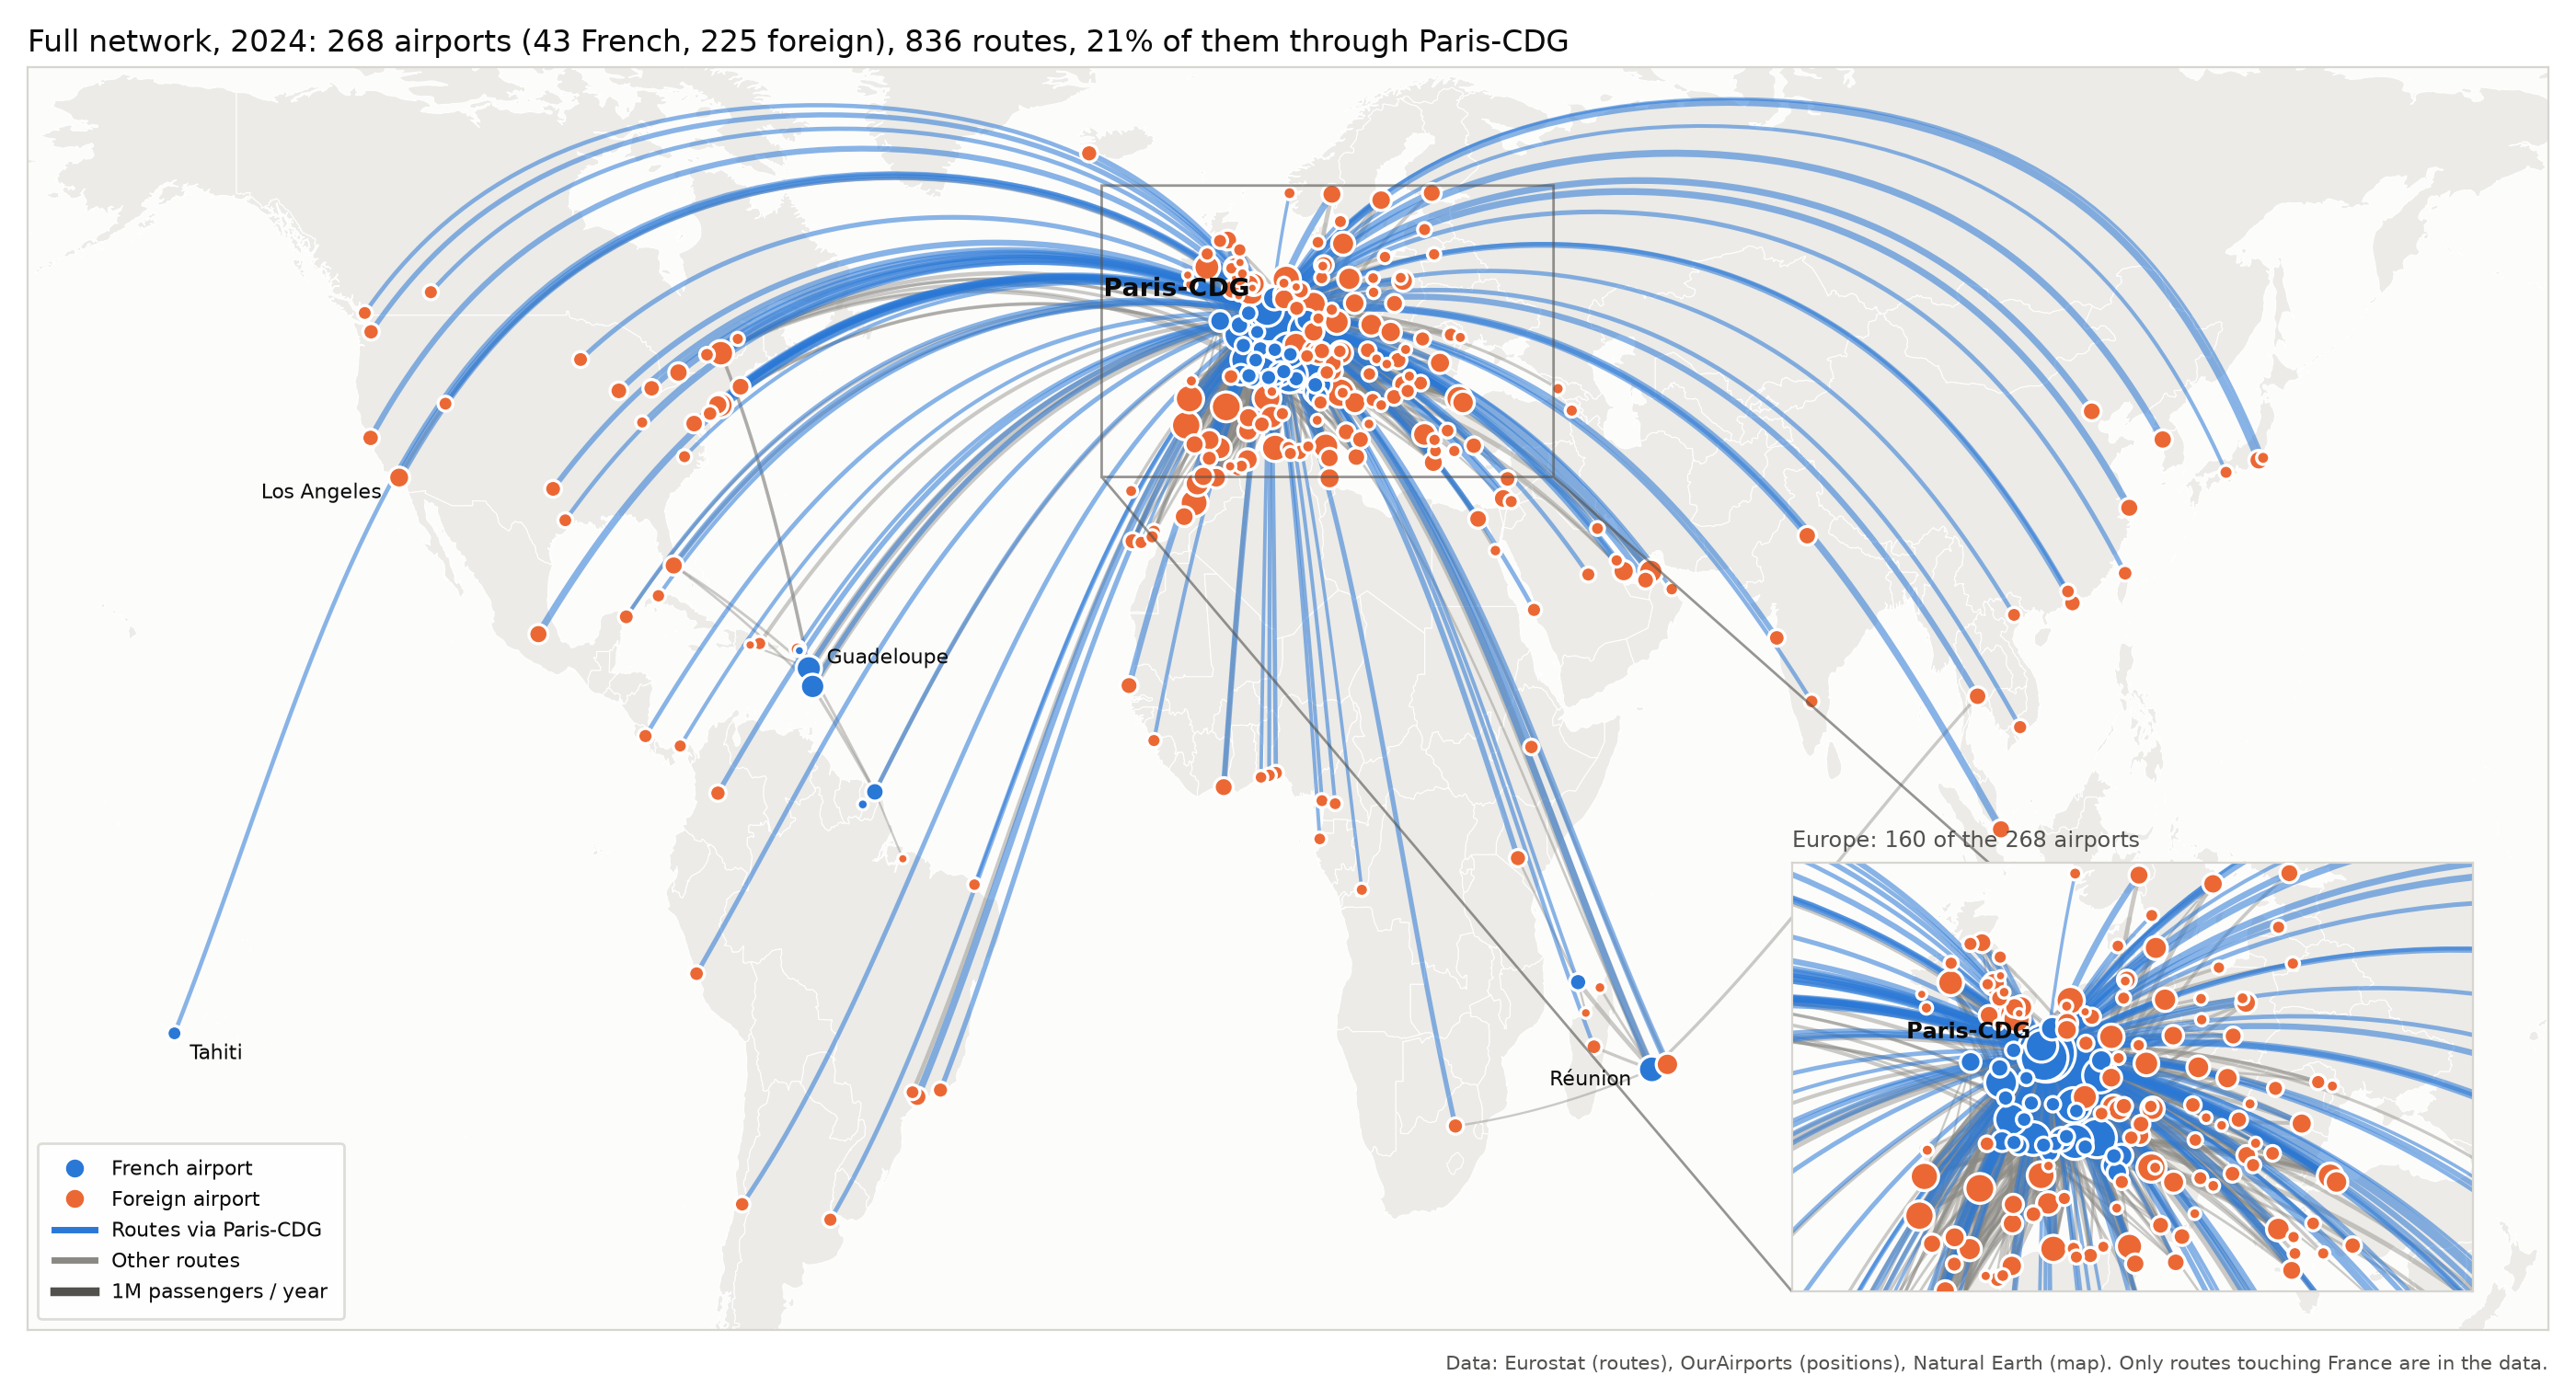

In [5]:
show('map_full_2024')

268 airports (43 French, 225 foreign) and 836 routes form a single connected component, but a sparse one (density 0.023): the median airport has 2 routes and 44 % of the airports are leaves, almost all foreign airports linked to a single French airport. The diameter is 6 hops, the radius 3, and the **centre is CDG and Orly**. CDG is by far the worst articulation point: removing it cuts 77 airports off the network (Beauvais, the next one, cuts off 10).

## 3. Centrality: CDG in a league of its own

In [6]:
import centrality

cent = centrality.run(YEAR)
display(pd.Series(cent["centralization"], name="Freeman centralization").to_frame())
cent["focus"][["name", "degree", "strength", "betweenness", "harmonic", "pagerank", "coverage",
               "degree_vs_cdg", "strength_vs_cdg", "betweenness_vs_cdg"]]

,Freeman centralization
degree_centralization,0.652
betweenness_centralization,0.647


,name,degree,strength,betweenness,harmonic,pagerank,coverage,degree_vs_cdg,strength_vs_cdg,betweenness_vs_cdg
icao,,,,,,,,,,
LFPG,PARIS-CHARLES DE GAULLE,179,66139627,0.651,0.816,0.203,0.941,1.000,1.000,1.000
LFPO,PARIS-ORLY,85,29196429,0.138,0.583,0.079,0.881,0.475,0.441,0.212
LFMN,NICE-COTE D'AZUR,58,13105344,0.033,0.591,0.033,0.888,0.324,0.198,0.051
LFLL,LYON-ST-EXUPERY,49,8339404,0.023,0.558,0.021,0.800,0.274,0.126,0.036
LFSB,BALE-MULHOUSE,68,8200310,0.118,0.601,0.027,0.921,0.380,0.124,0.181
LFOB,BEAUVAIS-TILLE,57,5910927,0.107,0.493,0.025,0.902,0.318,0.089,0.164
LFML,MARSEILLE-PROVENCE,52,8830631,0.034,0.573,0.023,0.793,0.291,0.134,0.052
LFBO,TOULOUSE-BLAGNAC,45,6936591,0.028,0.566,0.018,0.883,0.251,0.105,0.043
LFRS,NANTES-ATLANTIQUE,47,6122903,0.020,0.555,0.015,0.875,0.263,0.093,0.031


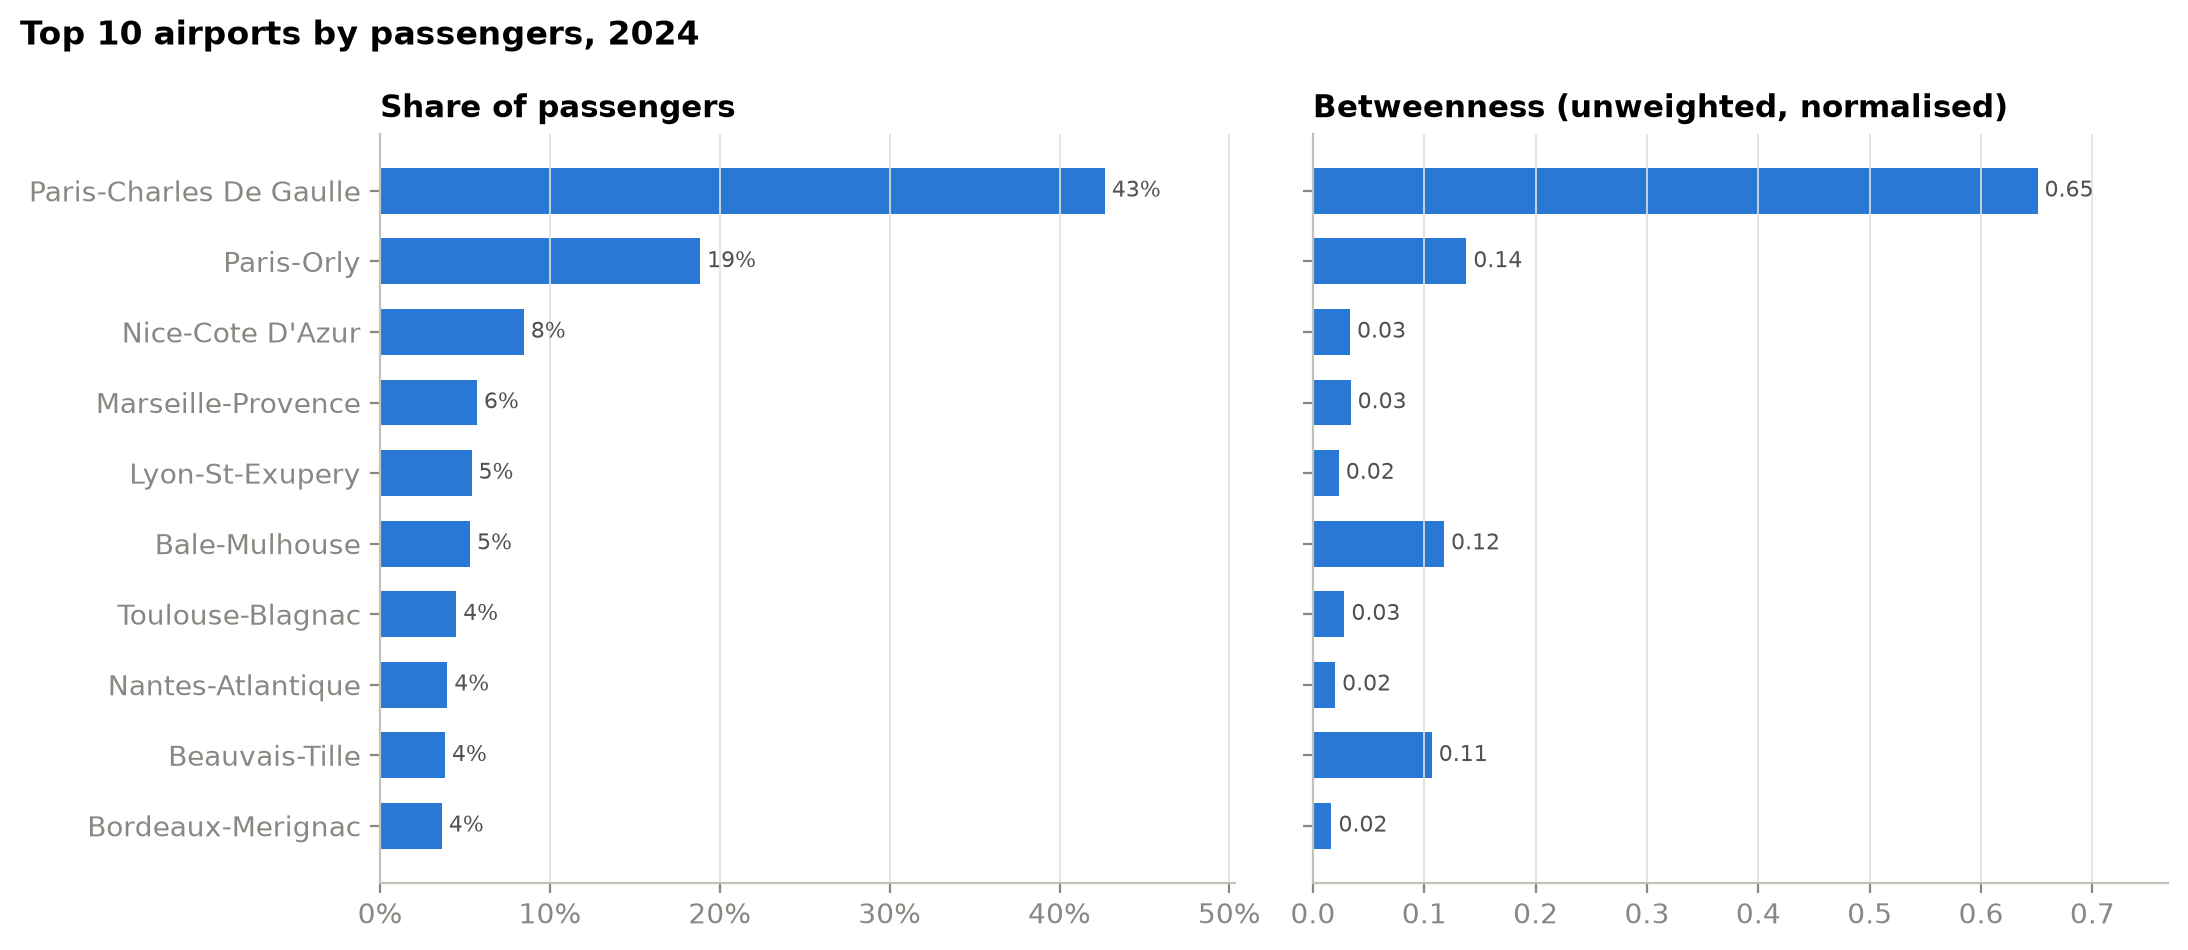

In [7]:
show('centrality_2024')

In [8]:
display(Markdown("**Robustness: CDG's betweenness with and without single-route foreign airports**"))
display(cent["robustness"])
display(Markdown("**Gateways: airports whose betweenness rank is much higher than their degree rank**"))
cent["gateways"].head(5)

**Robustness: CDG's betweenness with and without single-route foreign airports**

,variant,nodes,edges,cdg_betweenness,top_others,degree_centralization,betweenness_centralization
0,full graph,268,836,0.651,"LFPO 0.14, LFSB 0.12, LFOB 0.11",0.652,0.647
1,without single-route foreign airports,153,721,0.368,"LFPO 0.19, LFSB 0.11, LFMN 0.07",0.624,0.362
2,French airports only,43,136,0.255,"LFPO 0.17, LFML 0.12, LFKF 0.09",0.366,0.235


**Gateways: airports whose betweenness rank is much higher than their degree rank**

,name,zone,degree,rank_degree,betweenness,rank_betweenness,rank_gap
icao,,,,,,,
TFFG,ST-MARTIN-GRAND-CASE,overseas,3,97,0.007,28,69
FMCZ,MAYOTTE-MARCEL HENRY,overseas,4,87,0.008,27,60
SOCA,CAYENNE-FELIX EBOUE,overseas,6,64,0.015,14,50
LFTH,TOULON-HYERES,metro,5,72,0.005,31,41
LFBE,BERGERAC-DORDOGNE-PERIGORD,metro,8,48,0.020,10,38


CDG has 179 routes (21 % of all routes), 43 % of the passengers and a betweenness of 0.65; the next airports, Orly (0.14), Bâle-Mulhouse (0.12) and Beauvais (0.11), are five times lower. Betweenness centralisation is 0.65 (1 = perfect star). The Eurostat routes capture 79 to 94 % of the real traffic of the main airports (column `coverage`).

Part of CDG's betweenness comes from the foreign airports that only connect to it: without single-route foreign airports it drops to 0.37, still twice Orly's 0.19. Beauvais (Ryanair's Paris base) and Bâle-Mulhouse (easyJet) are the low-cost hubs of the network. Small overseas airports (St-Martin, Mayotte, Cayenne) matter more than their degree suggests: they are bridges inside their region.

## 4. Two networks in one: international vs domestic

In [9]:
import views

vw = views.run(YEAR)
display(vw["comparison"])
display(pd.Series(vw["intl_summary"], name="international").to_frame())
vw["intl_by_distance"]

view,full network,domestic
nodes,268,43
edges,836,136
density,0.023,0.151
components,1,5
isolated_airports,0,4
lcc_nodes,268,39
diameter_lcc,6,6
radius_lcc,3,3
center_lcc,"LFPG, LFPO","LFPG, LFPO"
avg_shortest_path_lcc,2.523,2.258


,international
international_routes,700.000
foreign_destinations,225.000
cdg_passenger_share,0.452
destinations_only_via_cdg,76.000


,routes,destinations,passengers,cdg_routes,cdg_passenger_share,destinations_only_via_cdg
band,,,,,,
"short (<1,500 km)",449,119,78528297,57,0.323,11
"medium (1,500-4,000 km)",155,60,23535782,26,0.348,5
"long (>4,000 km)",96,77,27746632,75,0.907,60


In [10]:
display(vw["domestic_centrality"].head(8)[["name", "degree", "strength", "betweenness", "harmonic", "pagerank"]])
vw["domestic_resilience"]

,name,degree,strength,betweenness,harmonic,pagerank
icao,,,,,,
LFPG,PARIS-CHARLES DE GAULLE,21,7408948,0.255,0.690,0.128
LFPO,PARIS-ORLY,17,8789056,0.172,0.639,0.148
LFML,MARSEILLE-PROVENCE,17,3282100,0.117,0.637,0.063
LFKF,FIGARI-SUD-CORSE,12,724049,0.093,0.581,0.019
LFLL,LYON-ST-EXUPERY,17,2256450,0.064,0.629,0.042
SOCA,CAYENNE-FELIX EBOUE,5,482070,0.044,0.474,0.014
LFOB,BEAUVAIS-TILLE,2,74800,0.043,0.370,0.015
TFFG,ST-MARTIN-GRAND-CASE,3,208479,0.043,0.344,0.011


,removed,components,isolated,lcc_nodes,lcc_share_of_airports,passengers_kept_in_lcc
0,none,5,4,39,0.907,1.000
1,CDG,7,6,36,0.837,0.706
2,Orly,6,5,37,0.860,0.651
3,CDG + Orly,9,7,28,0.651,0.331


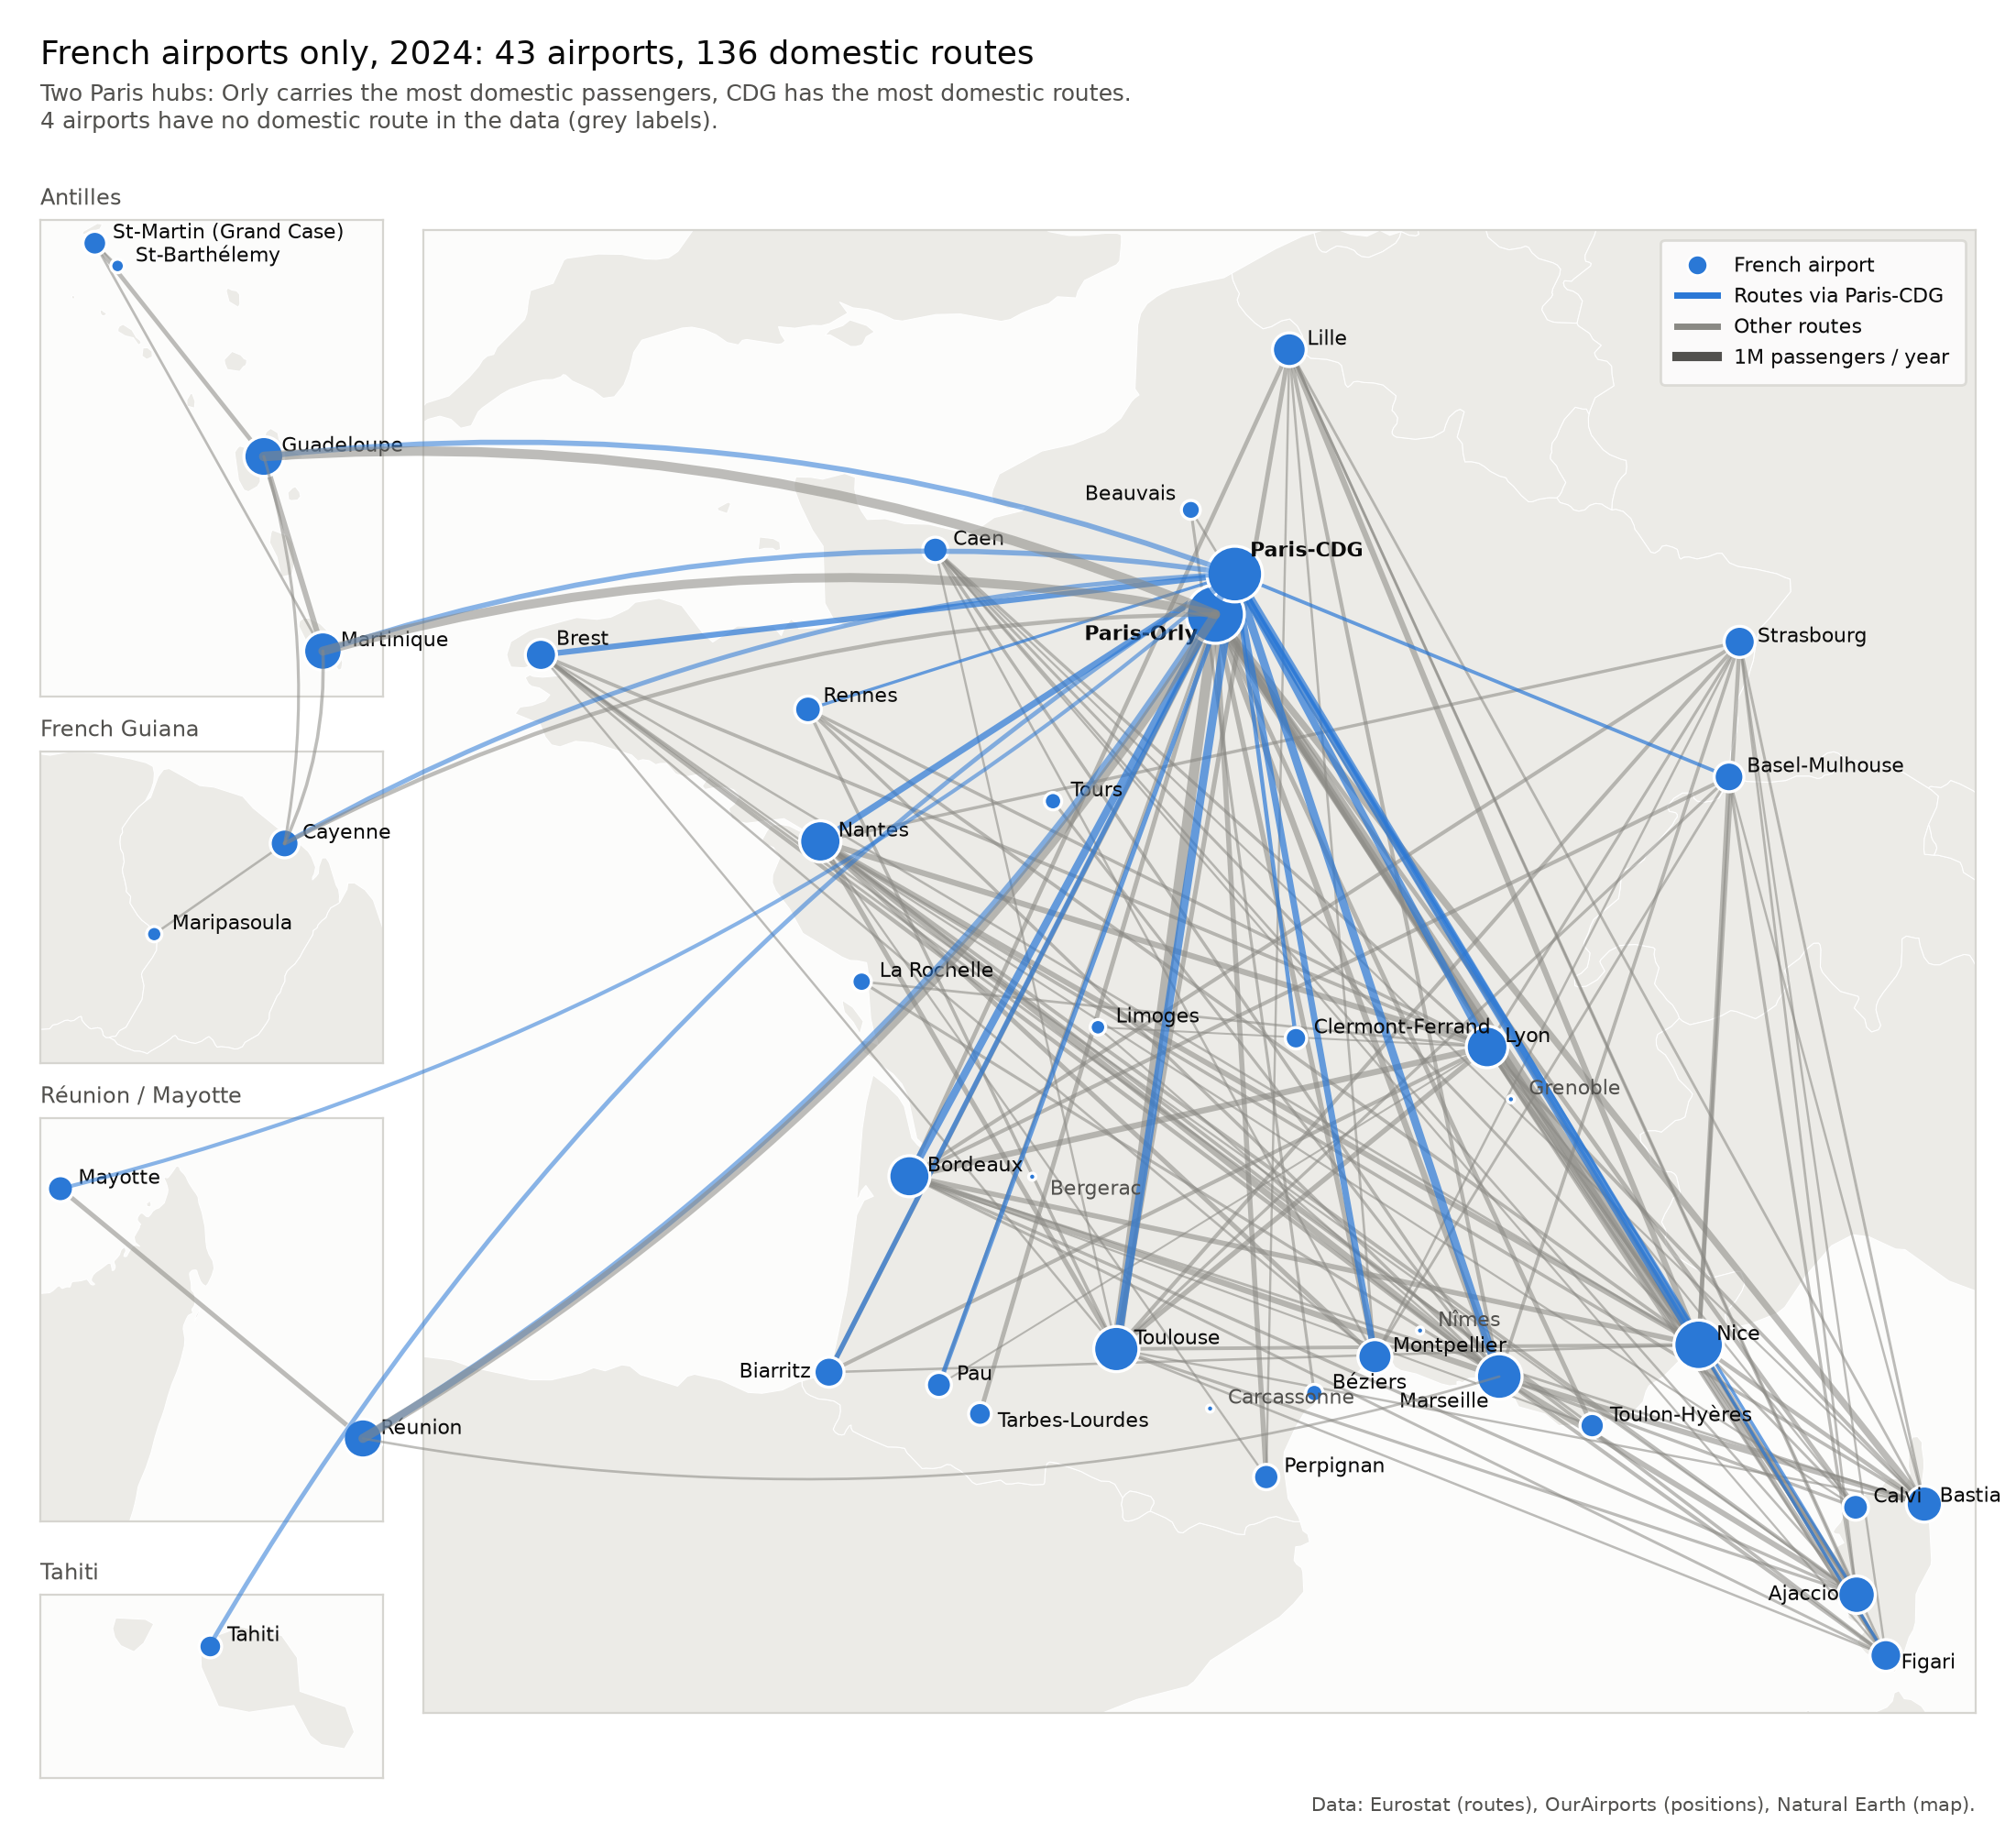

In [11]:
show('map_french_2024')

The centralisation on CDG is an **international, long-haul** phenomenon. CDG carries 45 % of the international passengers, but **91 % of the long-haul passengers** (over 4,000 km), and **76 foreign destinations are reachable only through CDG**, 60 of them long-haul.

The domestic network (43 French airports, 136 routes) is far less centralised: betweenness centralisation 0.24 against 0.65 for the full network. **Paris has two domestic hubs**: CDG has the most domestic routes (21) and the highest betweenness (0.26), Orly carries the most domestic passengers (8.8 M against 7.4 M). Losing Orly costs slightly more domestic traffic than losing CDG (65 % vs 71 % of domestic passengers kept in the main component); losing both leaves 33 %.

## 5. Is it surprising? Degree-preserving null model

Random graphs that keep every airport's number of routes (double-edge swaps, never creating a foreign-foreign route, which the data cannot contain). For each metric: real value, mean and standard deviation over the random graphs, z-score and empirical p-value.

In [12]:
import null_model

null_table, null_samples = null_model.run(YEAR, N_NULL)
null_table

,view,metric,real,null_mean,null_sd,z,p_two_sided
0,full network,cdg_betweenness,0.651,0.588,0.008,7.376,0.000
1,full network,orly_betweenness,0.138,0.148,0.015,-0.695,0.520
2,full network,betweenness_centralization,0.647,0.585,0.009,7.325,0.000
3,full network,degree_assortativity,-0.424,-0.392,0.003,-11.637,0.000
4,full network,hub_density_top10,0.511,0.839,0.046,-7.096,0.000
5,full network,modularity_louvain,0.341,0.280,0.004,16.608,0.000
6,full network,communities,7.000,8.894,0.953,-1.987,0.124
7,full network,components,1.000,1.072,0.266,-0.270,1.000
8,full network,avg_shortest_path_lcc,2.523,2.416,0.012,8.797,0.000
9,full network,diameter_lcc,6.000,4.842,0.416,2.781,0.040


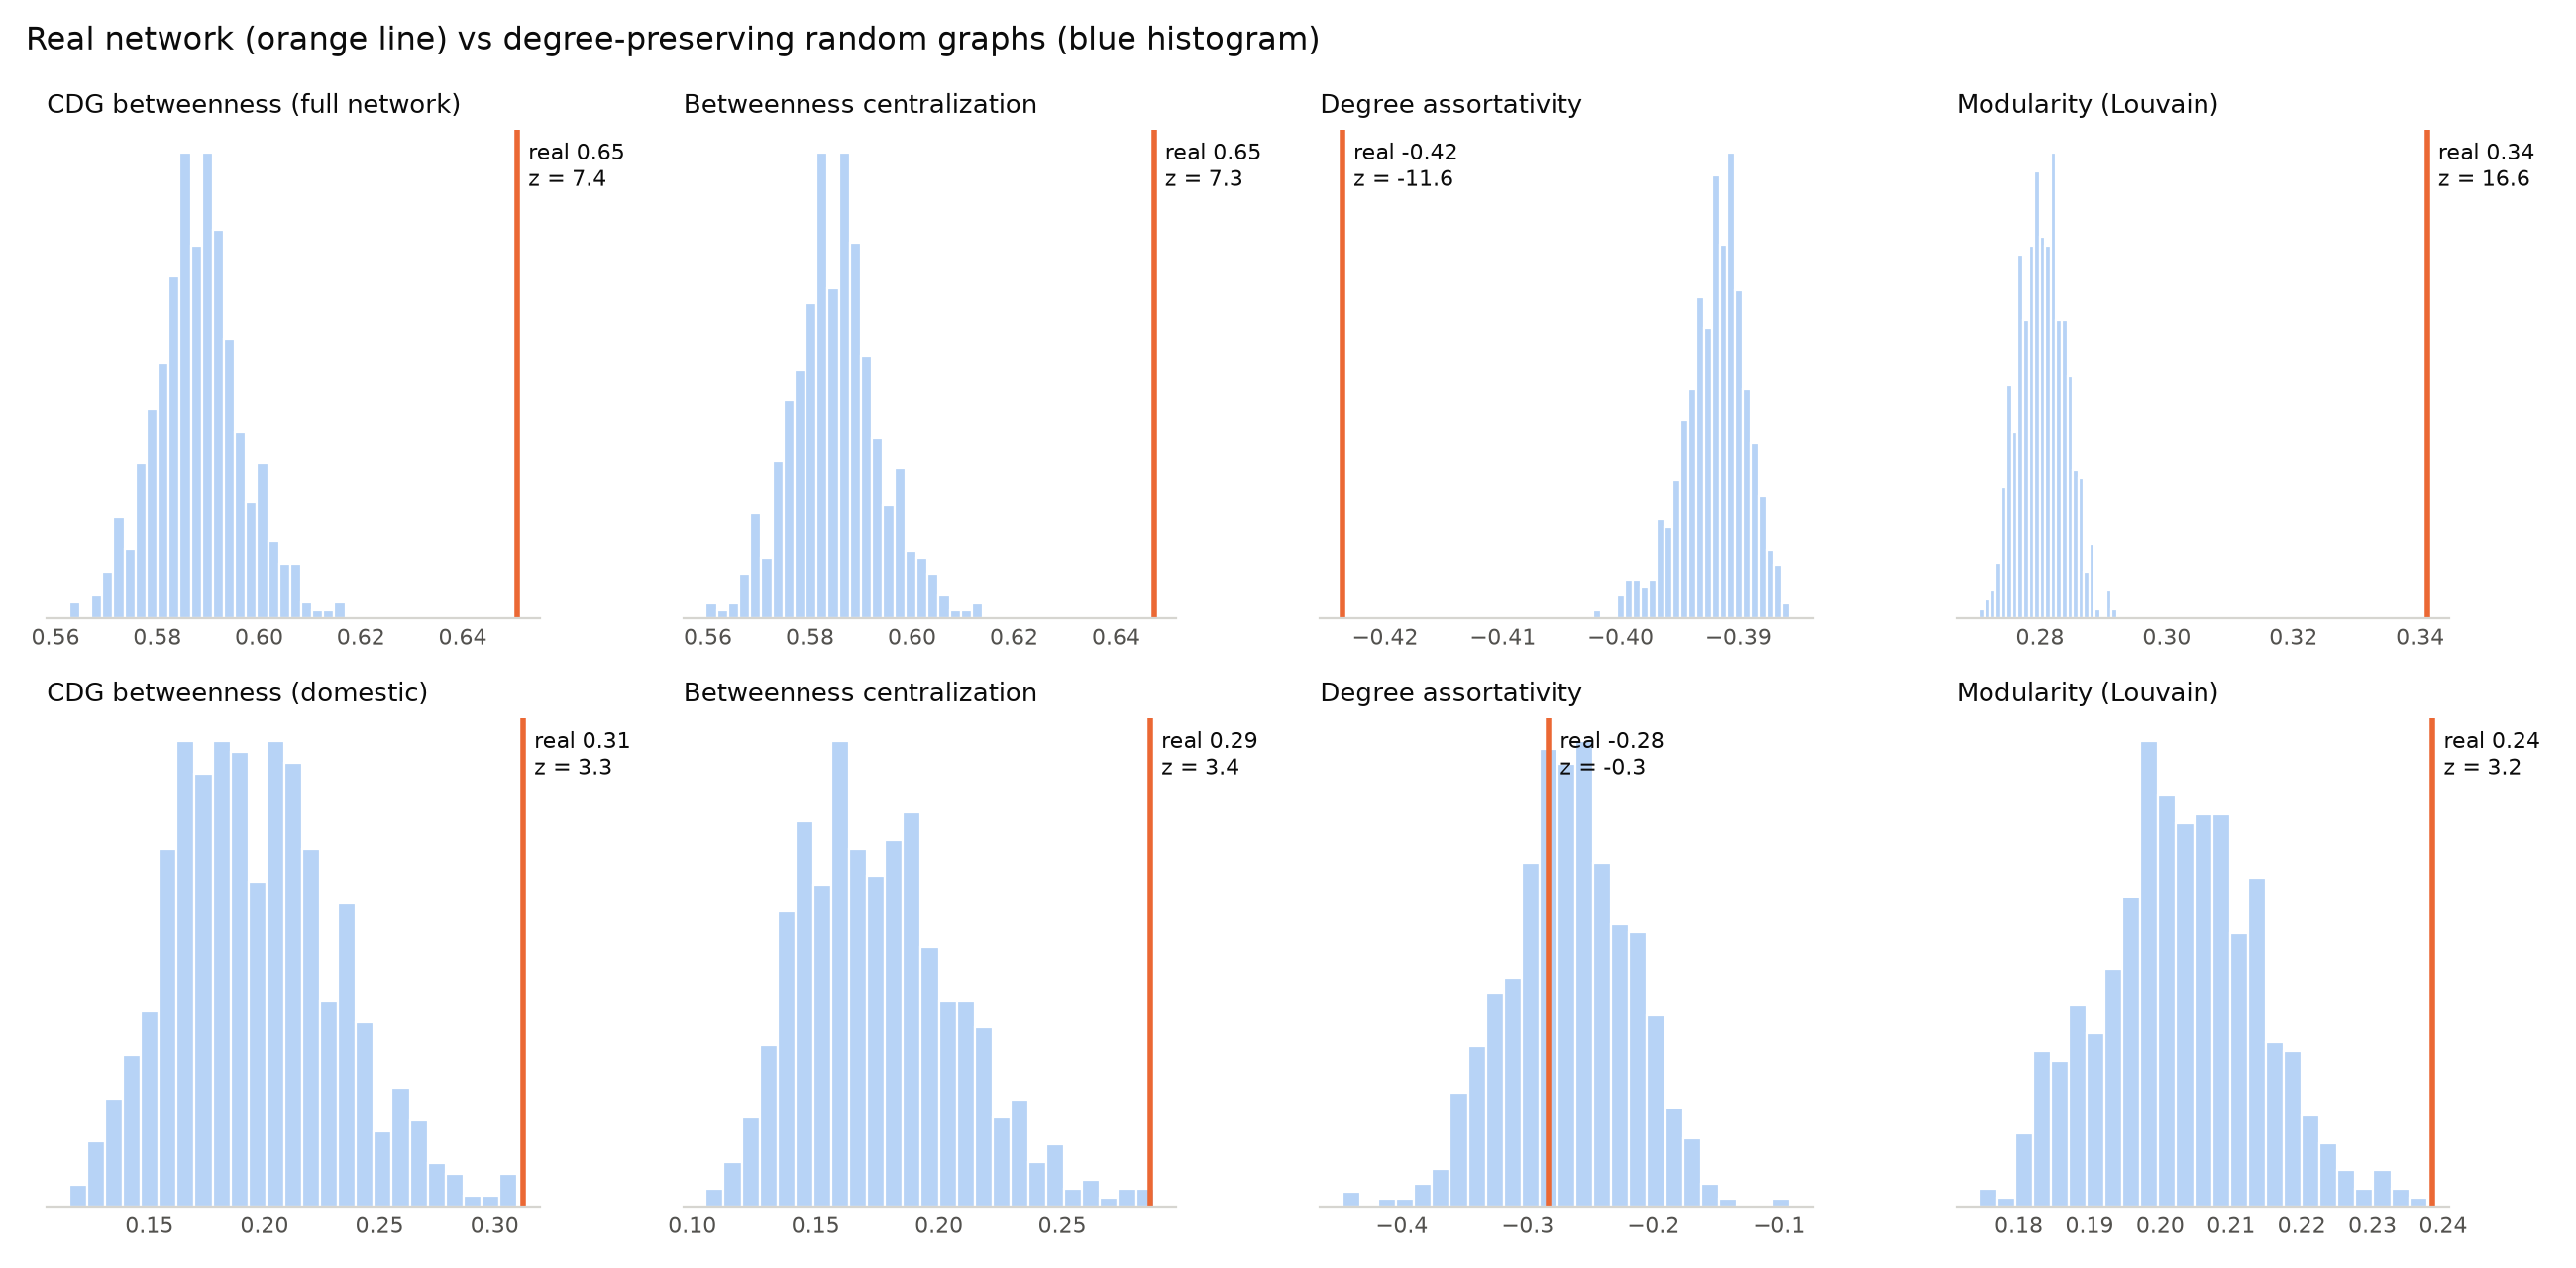

In [13]:
show('null_model_2024')

**CDG is more central than its number of routes alone would make it**: betweenness 0.65 against 0.59 ± 0.01 in random graphs with the same degrees (z = 7.4, p < 0.002). The wiring matters: CDG is the only French link to many long-haul destinations, while in random graphs some of those routes would land on other French airports. The real network is also more hub-and-spoke than chance (assortativity -0.42 vs -0.39, z = -11.6), the big hubs are less connected to each other than chance (density among the top 10: 0.51 vs 0.84), and the community structure is clearly stronger (modularity 0.34 vs 0.28, z = 16.6). On the domestic network, CDG and Orly are both more central than chance. The domestic null model runs on the 39 French airports with at least one domestic route (the 4 others cannot be rewired), so its real values differ from section 4, which keeps all 43 airports (betweenness centralisation 0.29 vs 0.24, CDG betweenness 0.31 vs 0.26).

## 6. Resilience: robust yet fragile

Airports are removed and the remaining graph is measured: fixed scenarios (CDG, Orly, CDG + Orly) against random removals of the same size, and removal curves (static targeted orders by degree, passengers or betweenness; an adaptive attack that recomputes betweenness after each removal; random failures, mean of 100 orders).

In [14]:
import resilience

scen = resilience.scenarios(G)
scen[["scenario", "removed", "lcc_share", "isolated", "french_pairs_connected", "passengers_kept", "lcc_diameter"]]

,scenario,removed,lcc_share,isolated,french_pairs_connected,passengers_kept,lcc_diameter
0,none,0,1.000,0.00,1.000,1.000,6.0
1,CDG,1,0.709,77.00,0.952,0.573,6.0
2,Orly,1,0.966,8.00,1.000,0.812,6.0
3,CDG + Orly,2,0.649,92.00,0.951,0.385,7.0
4,random 1 (mean of 100),1,0.996,0.12,1.000,0.994,6.0
5,random 2 (mean of 100),2,0.992,0.16,1.000,0.987,6.0


In [15]:
res_curves = resilience.curves(G)
res_curves[res_curves["removed"].isin([1, 2, 3, 5, 10, 20])].pivot(
    index="removed", columns="strategy", values="lcc_share")

strategy,betweenness,betweenness_adaptive,degree,passengers,random
removed,,,,,
1,0.709,0.709,0.709,0.709,0.996
2,0.649,0.649,0.649,0.649,0.989
3,0.590,0.590,0.590,0.623,0.979
5,0.466,0.466,0.474,0.567,0.969
10,0.347,0.299,0.299,0.299,0.940
20,0.224,0.119,0.172,0.261,0.889


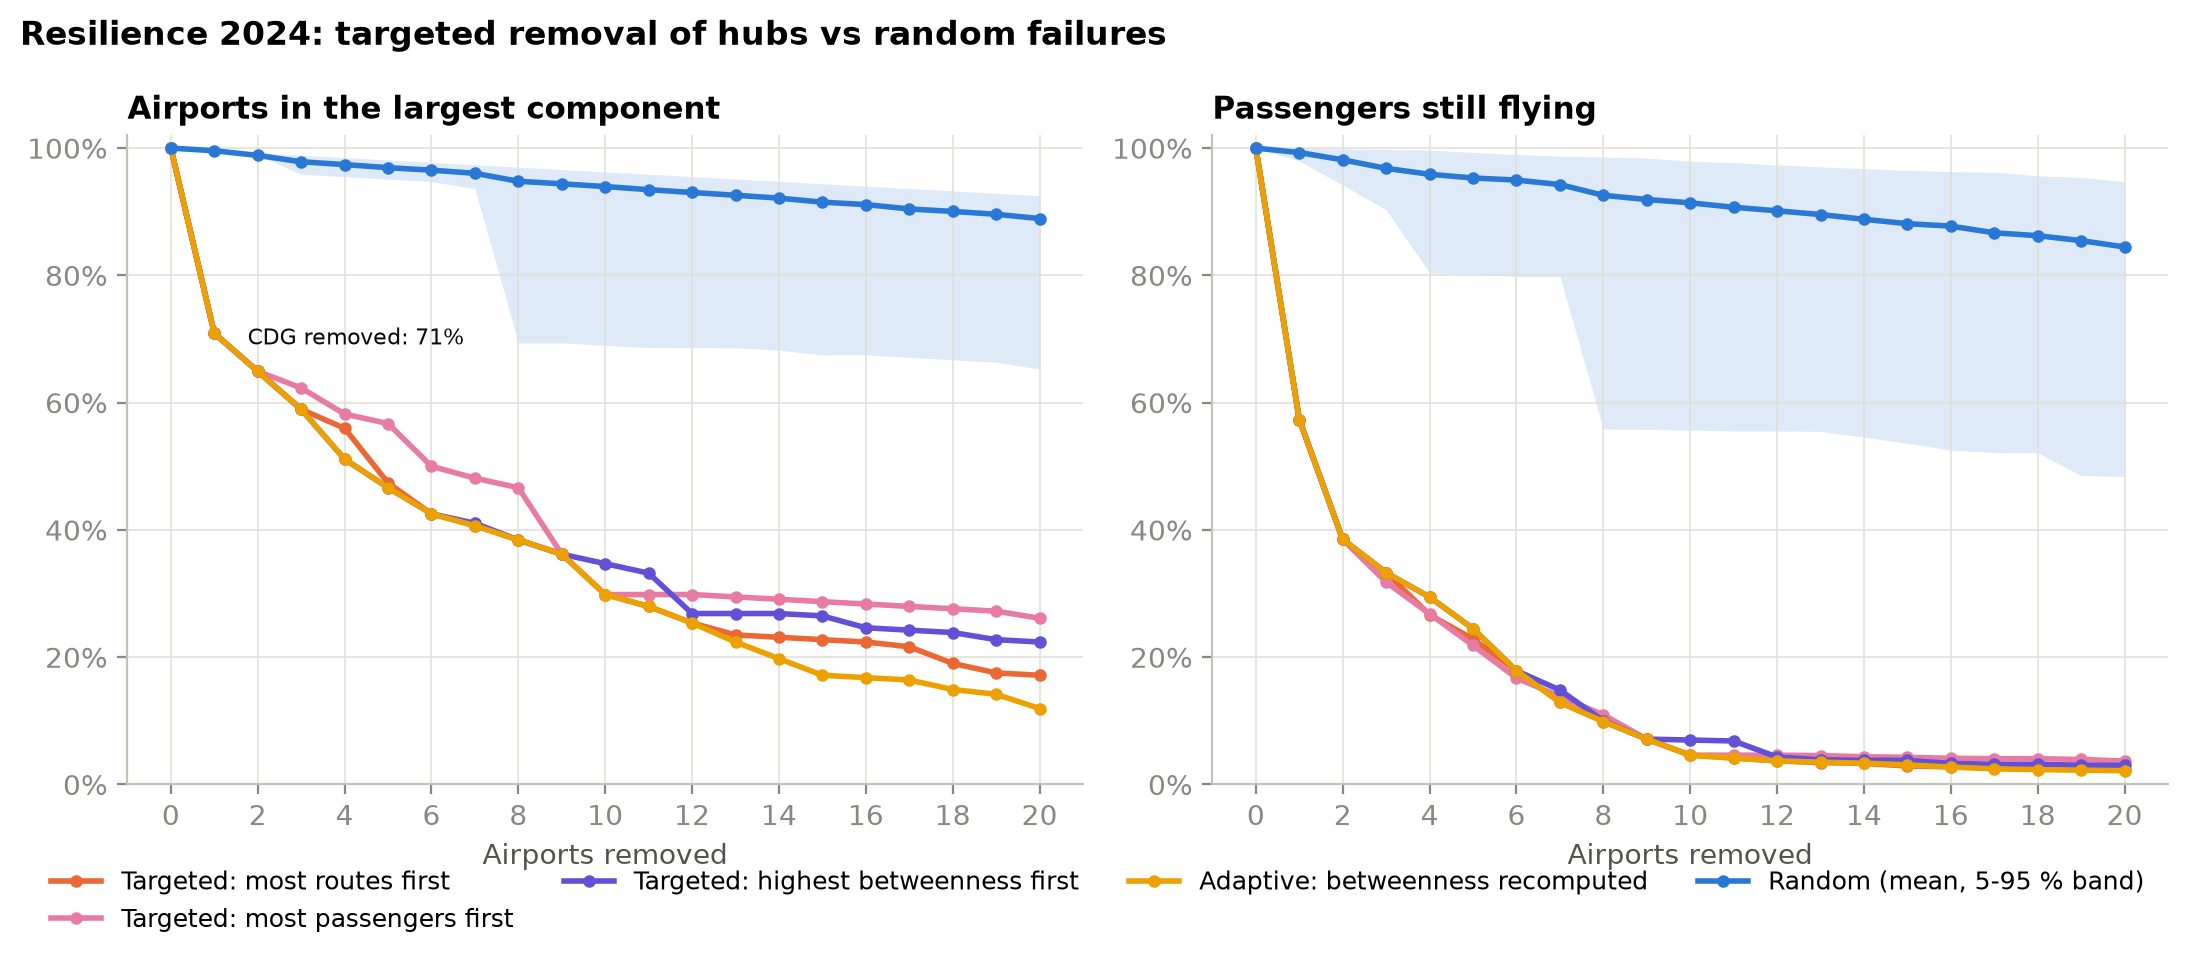

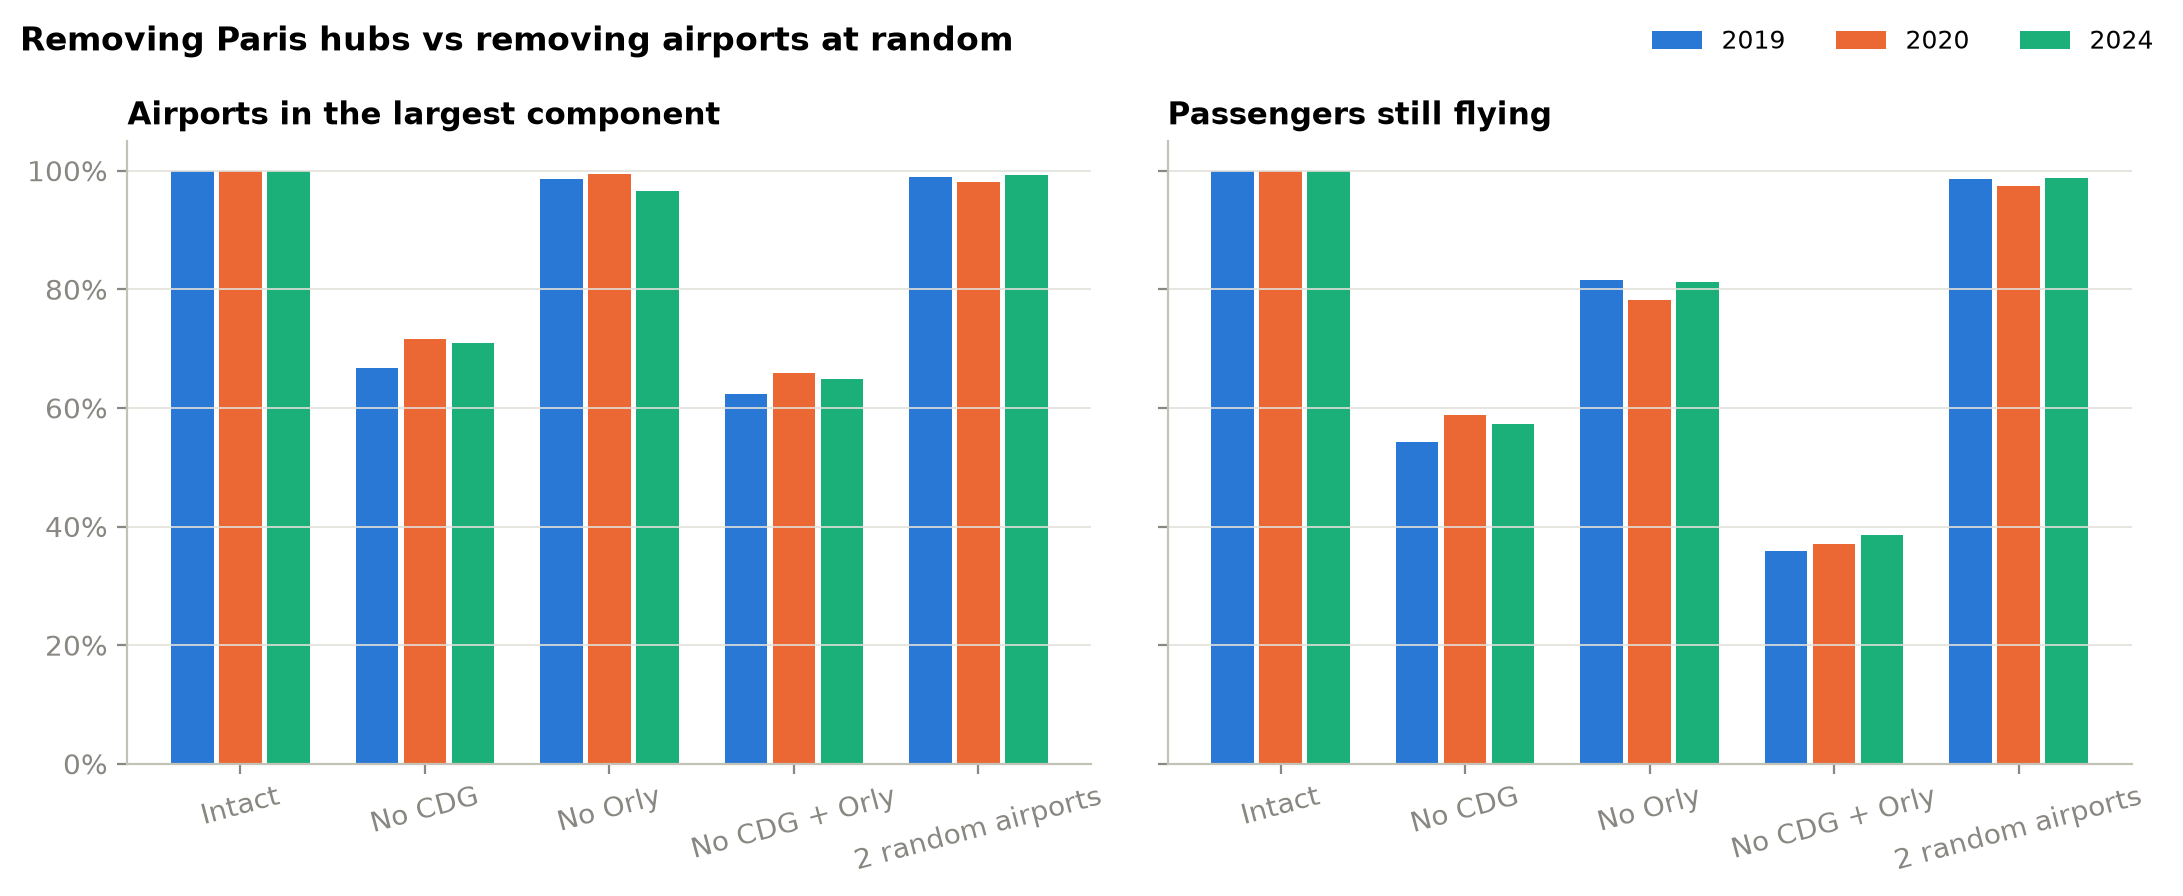

In [16]:
show('resilience_curves_2024')
show('resilience_scenarios')

Without CDG, the largest component keeps **71 %** of the airports, 77 airports are isolated and only **57 %** of the passengers keep their route; removing one airport at random keeps 99.6 % of the airports and 99 % of the passengers. Without CDG and Orly: 65 % of the airports and **39 %** of the passengers. Five targeted removals bring the network below half of its airports, while five random removals leave 97 % connected; after ten removals, the adaptive attack leaves 30 % of the airports in the main component (static betweenness order: 35 %, static degree order: 30 %), random failures 94 %. In passengers, ten removals by degree, by passengers or by adaptive betweenness leave 5 % of the traffic (7 % with the static betweenness order), against 91 % for random failures. This is the classic *robust-yet-fragile* signature of a hub-and-spoke network.

The French airports themselves stay connected to each other much better than the foreign ones (95 % of French pairs still connected without CDG): the fragility is first an **international** fragility, as foreign airports served only from CDG lose their link to France.

## 7. Communities

Louvain (`networkx.community.louvain_communities`, resolution 1, `seed=42`), weighted by passengers and unweighted, with modularity, stability over 20 seeds (adjusted Rand index) and the agreement between the two weightings.

In [17]:
import communities

comm_tab, comm_summary = communities.analyse(YEAR)
display(pd.DataFrame(comm_summary)[["weighted", "n_communities", "modularity", "cdg_orly_same",
                                    "ari_mean", "ari_min", "ari_weighted_vs_unweighted"]])
comm_tab[comm_tab["weighted"]][["community", "size", "metro", "overseas", "foreign",
                                "top_regions", "main_airports", "strength_share"]]

,weighted,n_communities,modularity,cdg_orly_same,ari_mean,ari_min,ari_weighted_vs_unweighted
0,True,5,0.283,False,0.862,0.767,0.433
1,False,7,0.341,False,0.885,0.727,0.433


,community,size,metro,overseas,foreign,top_regions,main_airports,strength_share
0,0,119,3,1,115,"Northern Europe (22), United States (17), Southern Europe & Mediterranean (13)","PARIS-CHARLES DE GAULLE [LFPG], İstanbul Airport [LTFM], Montreal / Pierre E...",0.387
1,1,80,22,6,52,"France (28), Southern Europe & Mediterranean (19), Northern Europe (10)","PARIS-ORLY [LFPO], MARSEILLE-PROVENCE [LFML], LYON-ST-EXUPERY [LFLL], TOULOU...",0.377
2,2,48,3,0,45,"Southern Europe & Mediterranean (31), Northern Europe (9), France (3)","BALE-MULHOUSE [LFSB], BEAUVAIS-TILLE [LFOB], Dublin Airport [EIDW], Berlin B...",0.092
3,3,16,6,0,10,"Northern Europe (8), France (6), Southern Europe & Mediterranean (2)","NICE-COTE D'AZUR [LFMN], BORDEAUX-MERIGNAC [LFBD], Amsterdam Airport Schipho...",0.131
4,4,5,0,2,3,"Southern & Indian Ocean Africa (3), France (2)","LA REUNION-ROLAND GARROS [FMEE], Sir Seewoosagur Ramgoolam International Air...",0.014


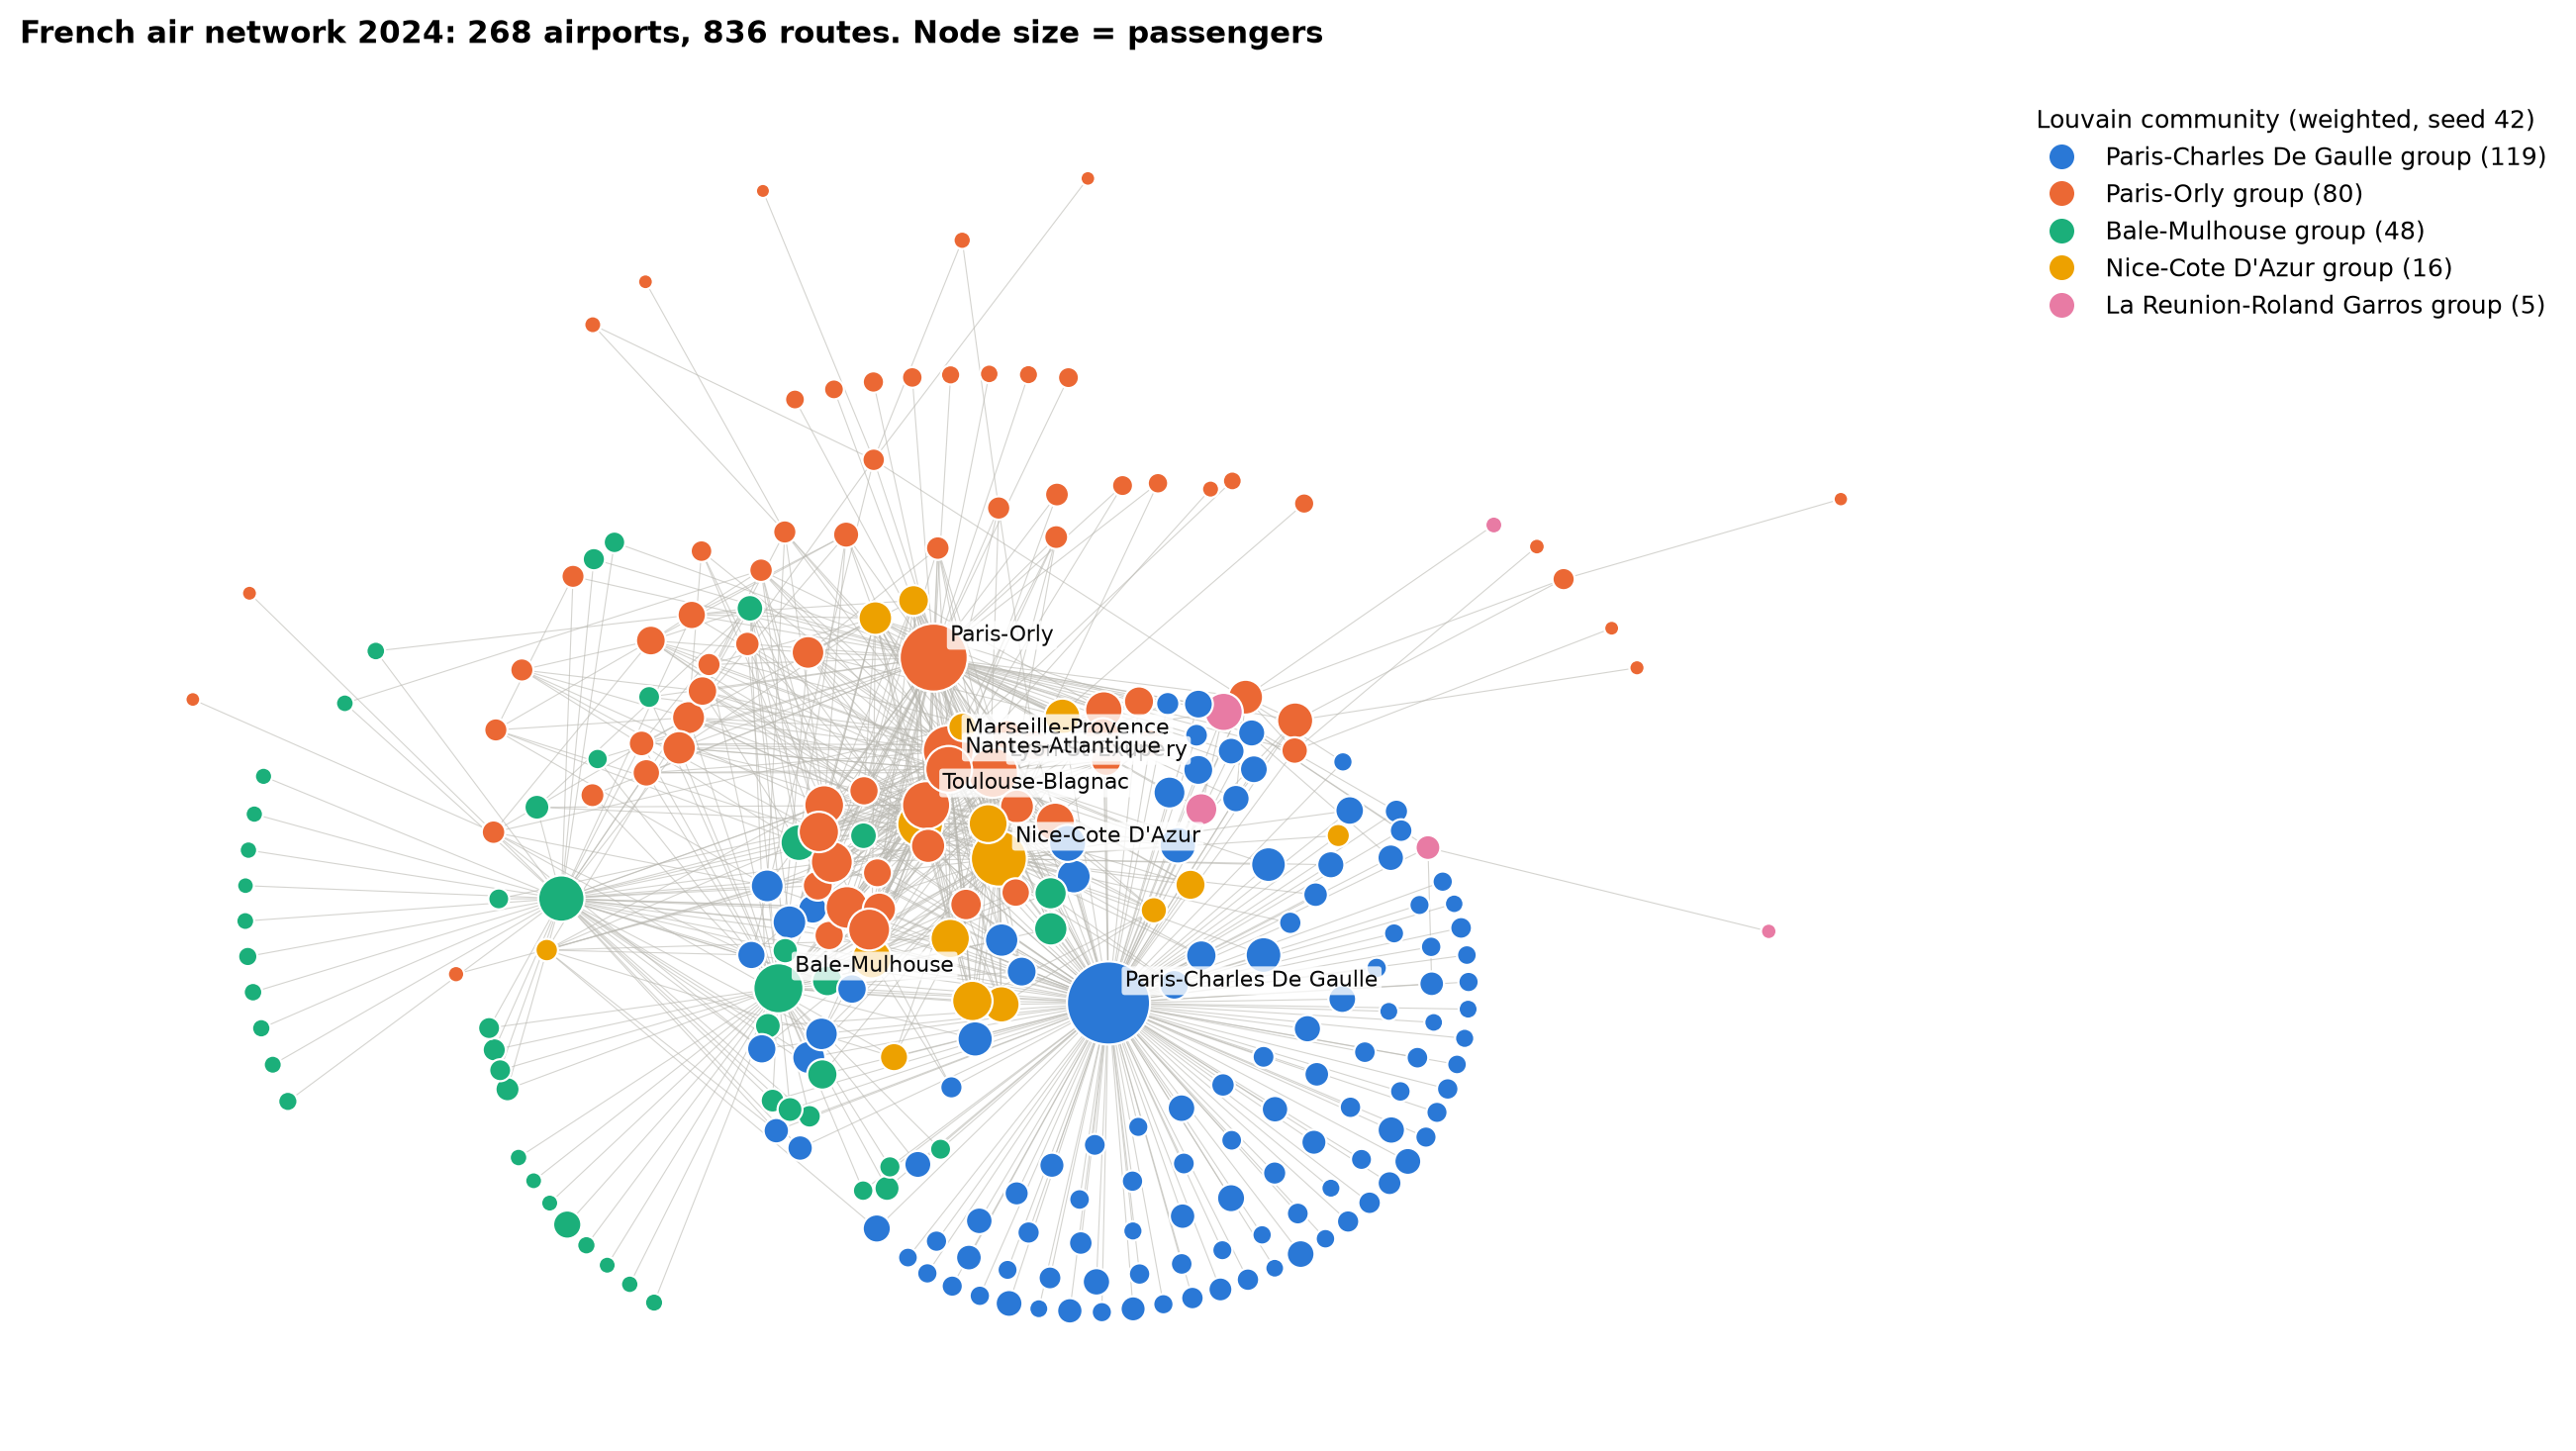

In [18]:
show('network_map_2024')

**Interpretation (2024, weighted by passengers; modularity 0.28).** The communities follow business models and markets:

- **CDG's international network** (119 airports, almost all foreign): long-haul (New York, Montréal, Istanbul) and the European hubs. CDG is France's gateway to the world.
- **Orly and the regional airports** (80 airports: Orly, Marseille, Lyon, Toulouse, Nantes, 6 overseas airports, Southern Europe and the Maghreb): domestic, overseas and Mediterranean point-to-point traffic.
- **The low-cost network** (48 airports): Bâle-Mulhouse and Beauvais with Dublin, Berlin, Istanbul Sabiha Gökçen and other low-cost bases. This group is invisible in the DGAC published data.
- **Nice and Bordeaux** (16 airports) with Amsterdam, Barcelona and London.
- **Réunion and the Indian Ocean** (5 airports): Réunion, Mayotte, Mauritius, Madagascar.

CDG and Orly fall in different communities in 2019, 2020 and 2024: the two Paris airports serve different markets. The partition is reasonably stable across seeds (mean ARI 0.86), but weighted and unweighted versions only partly agree (ARI 0.43); we present the weighted one because it follows the flows.

## 8. Comparison over time

In [19]:
import comparison

graphs = build_graphs(comparison.YEARS)
years = comparison.year_table(graphs)
years[["nodes", "edges", "passengers_m", "cdg_route_share", "cdg_passenger_share",
       "paris_passenger_share", "effective_airports", "betweenness_CDG", "betweenness_Orly",
       "n_communities", "modularity", "lcc_share_without_cdg", "passengers_kept_without_cdg"]].T

year,2019,2020,2024
nodes,279.000,155.000,268.000
edges,801.000,433.000,836.000
passengers_m,155.803,39.537,155.016
cdg_route_share,0.241,0.229,0.214
cdg_passenger_share,0.458,0.413,0.427
paris_passenger_share,0.641,0.630,0.615
effective_airports,14.532,15.349,16.012
betweenness_CDG,0.697,0.626,0.651
betweenness_Orly,0.102,0.067,0.138
n_communities,4.000,4.000,5.000


,from,to,kept,lost,gained,jaccard,note
0,2019,2020,418,383,15.0,0.512,NaN
1,2019,2024,660,141,176.0,0.676,NaN
2,2020,2024,404,29,432.0,0.467,NaN
3,2019,2024,265,118,NaN,NaN,routes lost in 2020: back in 2024 (kept) / still missing (lost)


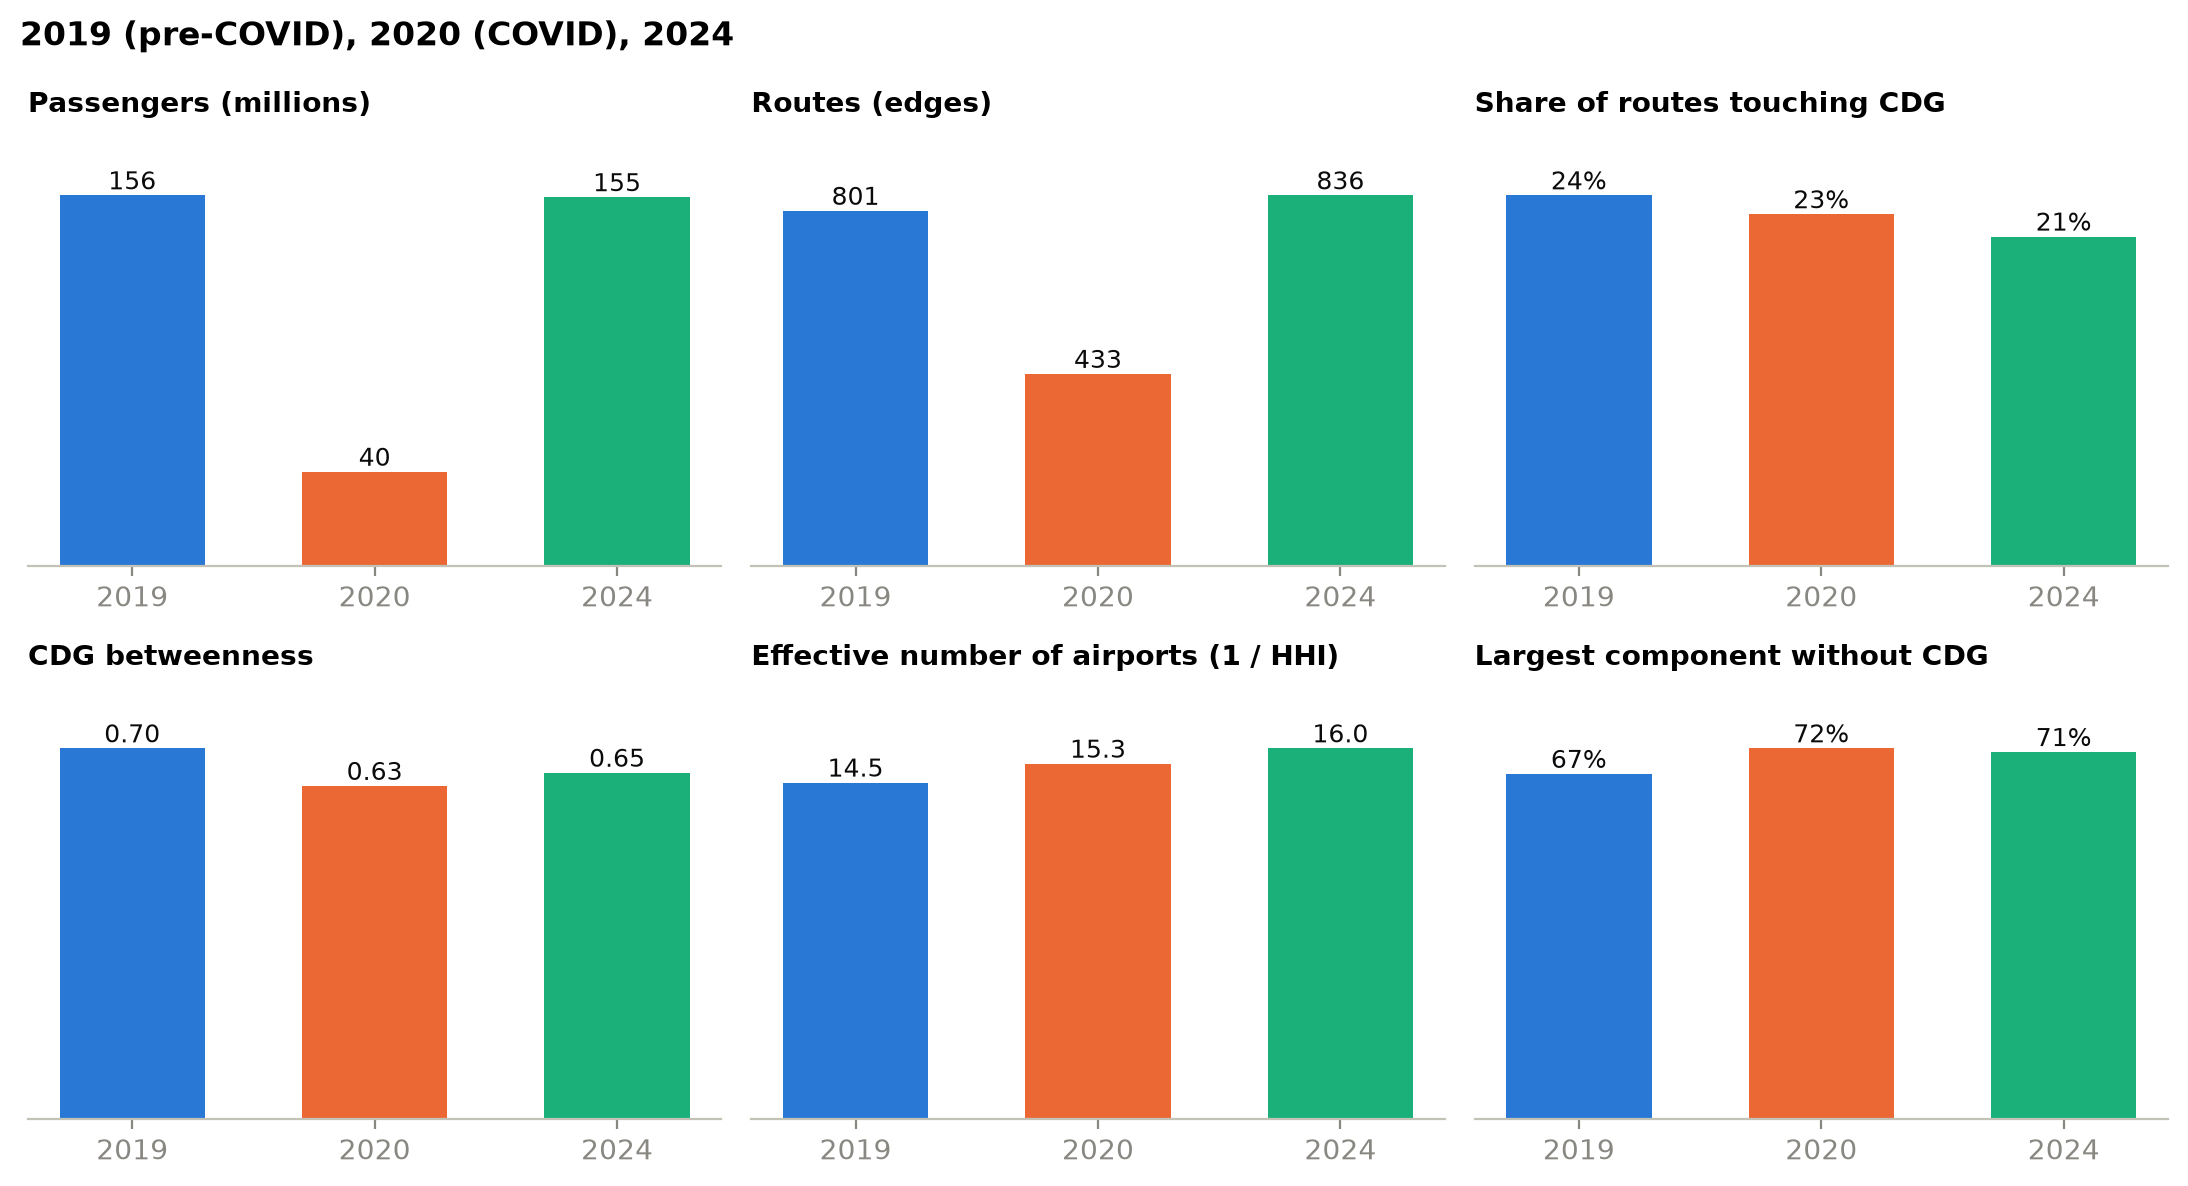

In [20]:
display(comparison.route_turnover(graphs))
show('comparison_years')

,reporting_airports,nodes,edges,passengers_m,cdg_betweenness,cdg_passenger_share,paris_passenger_share
year,,,,,,,
2010,40,257,635,108.477,0.682,0.497,0.701
2011,42,274,675,116.826,0.695,0.489,0.696
2012,43,277,694,119.941,0.670,0.482,0.679
2013,42,276,706,123.601,0.659,0.470,0.675
2014,42,284,733,128.278,0.641,0.469,0.672
2015,42,283,728,131.984,0.650,0.467,0.668
2016,42,281,754,137.433,0.645,0.450,0.663
2017,42,278,752,145.084,0.661,0.455,0.660
2018,42,279,788,152.836,0.673,0.447,0.651


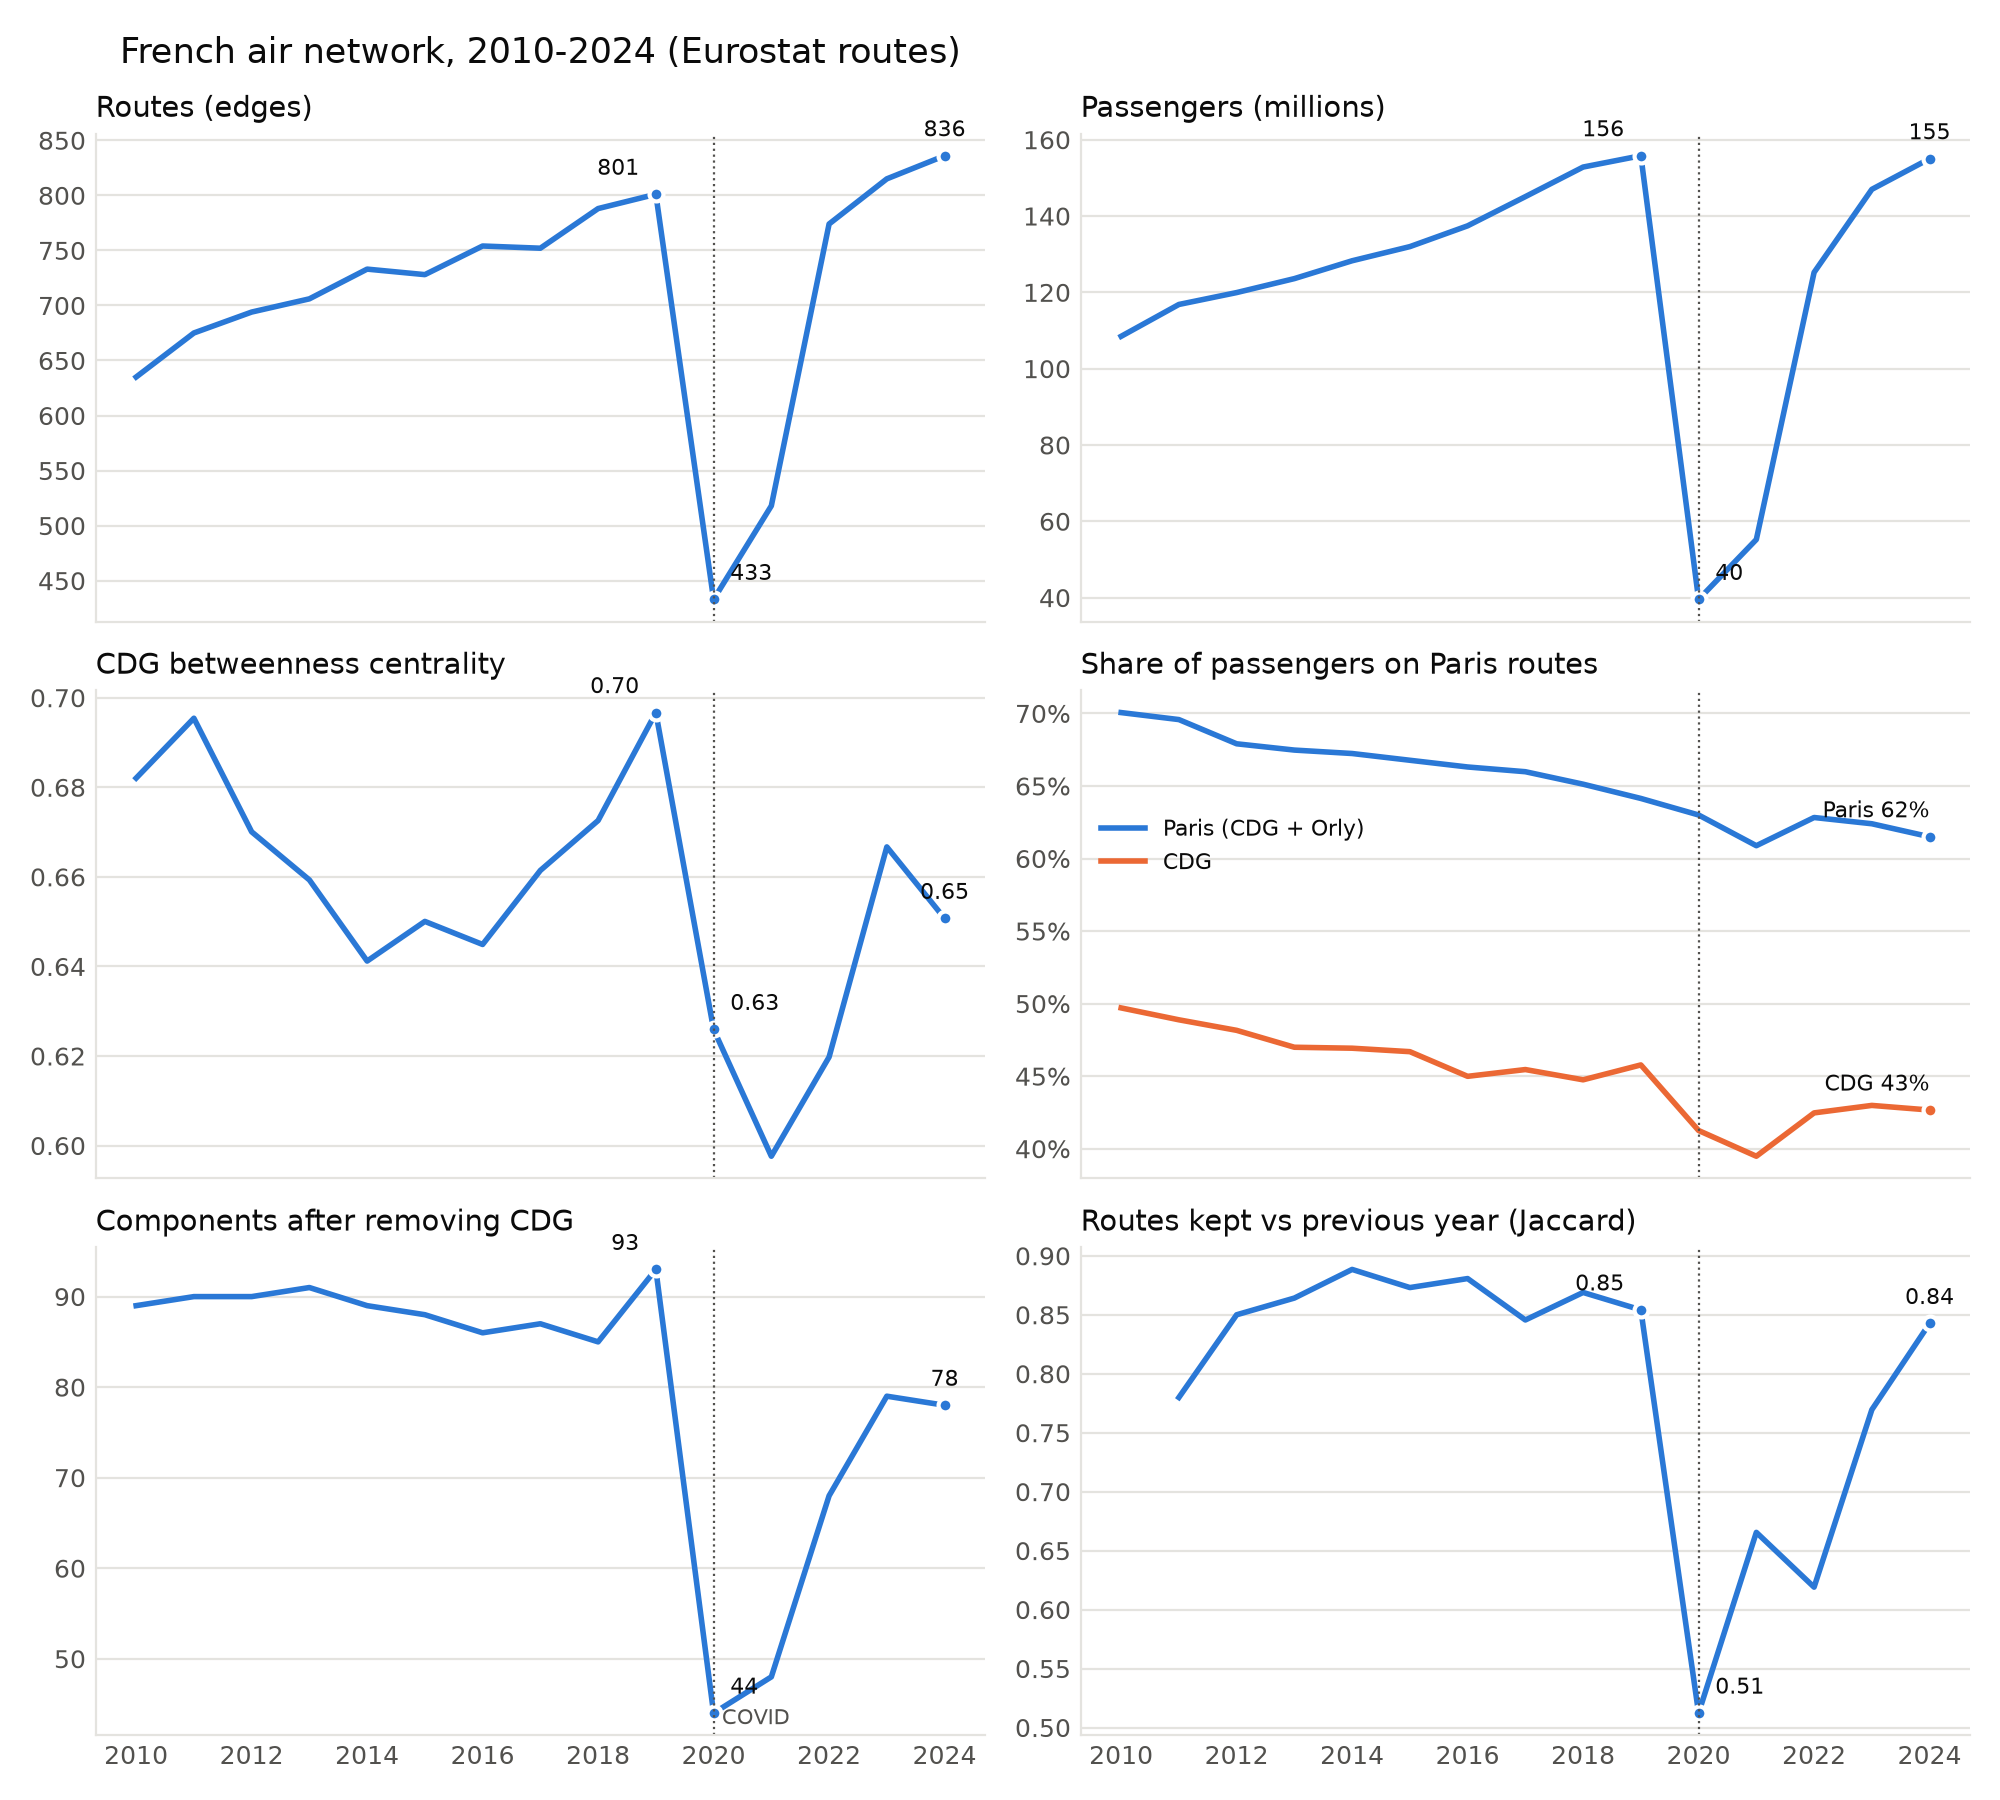

In [21]:
import time_series

ts = time_series.run()
display(ts[["reporting_airports", "nodes", "edges", "passengers_m", "cdg_betweenness",
            "cdg_passenger_share", "paris_passenger_share"]])
show('time_series')

Passengers fell from 155.8 M (2019) to 39.5 M (2020) and were back to 155.0 M in 2024 (-0.5 %), with more routes than before COVID (836 vs 801). **COVID did not reinforce CDG**: its betweenness went from 0.70 to 0.63 in 2020 and 0.65 in 2024, and the traffic is more spread out in 2024 than in 2019 (16.0 "effective airports" vs 14.5). Of the 383 routes lost in 2020, 265 were flown again in 2024. Caveat: in 2020-2021 only about 30 French airports reported to Eurostat (about 41 otherwise), so part of the routes lost in 2020 belong to small airports that stopped reporting.

Over 2010-2024, CDG's betweenness stays between 0.60 and 0.70, while **CDG's share of passengers fell from 50 % to 43 %** and the Paris share (CDG + Orly) from 70 % to 62 %: traffic grew faster in the regions (low-cost routes), but CDG kept its structural role.

## 9. Robustness and limitations

### Eurostat vs DGAC published routes

The same graph model and the same functions, applied to the DGAC published airport pairs (routes with at least 3 airlines).

In [22]:
import source_comparison

src = source_comparison.run()
display(src["coverage"].round(2))
display(src["indicators"].set_index(["year", "source"]).T)
src["routes"].set_index("year").T

,year,source,all French airports,CDG,Orly,Nice,Lyon,Toulouse,Bordeaux,Marseille,Nantes,Beauvais
0,2019,Eurostat,0.89,0.94,0.90,0.86,0.82,0.92,0.83,0.78,0.88,0.99
1,2019,DGAC published,0.47,0.57,0.44,0.54,0.42,0.48,0.37,0.31,0.40,0.00
2,2020,Eurostat,0.79,0.73,0.80,0.74,0.85,0.88,0.79,0.84,0.84,0.69
3,2020,DGAC published,0.36,0.44,0.39,0.27,0.35,0.36,0.27,0.27,0.27,0.00
4,2024,Eurostat,0.89,0.94,0.88,0.89,0.80,0.88,0.85,0.79,0.87,0.90
5,2024,DGAC published,0.43,0.54,0.45,0.52,0.31,0.25,0.19,0.20,0.34,0.00


year                                      2019                      2020                      2024               
source                                Eurostat DGAC published   Eurostat DGAC published   Eurostat DGAC published
airports                                   279            137        155            107        268            146
routes                                     801            293        433            183        836            280
domestic_routes                            143             56        125             40        136             38
passengers_m                           155.803          78.43     39.537         18.016    155.016          70.92
routes_under_1000_passengers                 0              4          0              6          0              3
cdg_routes                                 193            105         99             80        179            105
cdg_passenger_share                      0.458          0.556      0.413          0.547      0.427          0.538
effective_airports                      14.532         10.518     15.349          10.22     16.012          10.81
cdg_betweenness                          0.697          0.736      0.626           0.78      0.651          0.768
second_betweenness                   LFOB 0.14      LFPO 0.12  LFSB 0.21      LFPO 0.12  LFPO 0.14      LFPO 0.11
betweenness_centralization               0.694          0.732       0.62          0.775      0.647          0.764
domestic_betweenness_centralization       0.26          0.325      0.273          0.315      0.235          0.213
domestic_top_betweenness                  LFPO           LFPO       LFPG           LFPG       LFPG           LFPG
domestic_kept_without_cdg                0.777          0.774      0.775          0.771      0.706          0.806
domestic_kept_without_orly                0.57          0.548      0.595          0.569      0.651          0.493
lcc_share_without_cdg                    0.667           0.62      0.716          0.477      0.709          0.562
passengers_kept_without_cdg              0.542          0.444      0.587          0.453      0.573          0.462
passengers_kept_without_cdg_orly         0.359          0.265       0.37          0.223      0.385          0.251
lcc_after_10_adaptive                    0.244          0.022      0.161          0.028      0.299          0.027
communities                                  4              5          4              8          5              6
modularity                               0.289          0.345      0.303          0.404      0.283          0.358
null_cdg_betweenness_mean                  NaN            NaN        NaN            NaN      0.588          0.753
null_cdg_betweenness_p                     NaN            NaN        NaN            NaN        0.0           0.27

year,2019,2020,2024
routes_in_both,263,153,257
routes_only_eurostat,538,280,579
routes_only_dgac,30,30,23
passengers_only_eurostat_m,60.151,14.949,61.148
dgac_over_eurostat_median,0.77,0.702,0.664
dgac_over_eurostat_p10,0.146,0.191,0.145
biggest_routes_only_eurostat,"LFML-LFPO 884k, LFPG-OTHH 750k, LFPG-LSGG 727k, LFPG-ZBAA 682k, LFBD-LFPG 65...","LFML-LFPO 278k, LFKJ-LFPO 273k, LFPG-OTHH 256k, LFKB-LFPO 250k, DTTA-LFPO 24...","LFPG-OTHH 796k, LFBO-LFPG 787k, EGLL-LFMN 684k, LFBD-LFPG 629k, LFPG-SBGR 60..."
routes_reported_twice,115,99,97
report_gap_median,0.002,0.003,0.002
report_gap_p90,0.011,0.012,0.013


In 2024 the Eurostat routes capture **89 %** of the French airports' real traffic, the DGAC published routes **43 %** (Bordeaux 19 %, Marseille 20 %, Beauvais 0 %). DGAC hides 579 routes and 61 M passengers, mostly single-airline routes: Air France's regional routes to CDG, long-haul routes run by one airline (CDG-Doha, CDG-São Paulo), most low-cost routes. Eurostat is internally consistent: the two reports of a route agree within 0.2 % (median).

The main conclusions hold with both sources (CDG dominates, robust yet fragile, CDG and Orly in different communities, decentralised domestic network), but three change, which is why the project uses Eurostat:
- with DGAC, CDG's centrality looks fully explained by its degree (null model p = 0.27); with Eurostat it is not (p < 0.005);
- with DGAC, COVID seems to have raised CDG's betweenness (0.74 -> 0.78); with Eurostat it lowered it (0.70 -> 0.63): the DGAC rise came from the filter (less competition, more routes hidden);
- with DGAC the network looks much more fragile (adaptive attack: 3 % of airports left after 10 removals vs 30 %), because the low-cost bases that provide alternative paths are hidden.

### Limitations
- Only airports that report to Eurostat have all their routes; routes between two small non-reporting airports are missing. Bâle-Mulhouse's French and Swiss sectors add up to 8.2 M passengers on its routes, against 8.9 M in the DGAC airport series.
- Routes inside French Polynesia and New Caledonia are not covered (outside the EU statistical system); Tahiti appears only through its route to CDG.
- Annual data end in 2024; 31 confidential cells over 2010-2024; fewer reporting airports in 2020-2021.
- Annual, undirected graph: no direction, frequency or seasonality; no airline information. Distances in hops, not km or travel time.
- The resilience measures remove whole airports, not single routes.
- Louvain is randomised: results are given for `seed=42` with a stability check; small differences can appear between NetworkX versions.

## 10. Conclusion

1. **Centralised**: CDG has a fifth of the routes, 43 % of the passengers and a betweenness five times that of the next airport; it carries 91 % of the long-haul traffic and is the only French link to 76 foreign destinations. This is more than its number of routes implies (null model). Domestically, the network is decentralised, with two Paris hubs (CDG by routes, Orly by passengers).
2. **Fragile**: robust to random failures, but losing CDG cuts 77 airports off and 43 % of the passengers lose their route; losing CDG and Orly leaves 39 % of the traffic. The fragility is mostly international.
3. **Slowly less concentrated**: from 2010 to 2024 the Paris share of passengers fell from 70 % to 62 % with the growth of regional and low-cost traffic, and COVID did not reinforce CDG; CDG's structural role (betweenness 0.60-0.70) did not change.

*Explored and rejected (in the earlier DGAC version of the project): a bipartite projection of French airports through their shared foreign destinations, whose communities had a modularity close to 0.*

In [23]:
if REGENERATE_FIGURES:
    import figures, network_map
    figures.main(YEAR)
    coords, rings = network_map.load_coords(), network_map.load_countries()
    network_map.map_full(G, coords, rings, RESULTS / f"map_full_{YEAR}.png")
    network_map.map_french(G, coords, rings, RESULTS / f"map_french_{YEAR}.png")
    null_model.plot(null_table, null_samples, RESULTS / f"null_model_{YEAR}.png")
    time_series.plot(ts, RESULTS / "time_series.png")